# 01 · Data Analysis — Real Estate Investment Advisor
### Predicting Property Profitability & Future Value

**Notebook:** `01_Data_Analysis.ipynb` (Phase 2 of the project)  
**Dataset:** `india_housing_prices.csv` (250,000 rows × 23 columns)  
**Designed for:** a fresh Google Colab runtime, run cell by cell, top to bottom.

---

## 1. Project introduction

### Problem statement
Build a machine-learning application that helps a property investor decide whether to buy. The finished system should:
1. **Classify** whether a property is a *"Good Investment"* (yes / no).
2. **Predict** the estimated property price **5 years** from now.

A Streamlit app will show both answers, and MLflow will track the experiments. **This notebook covers only the data-analysis step.**

### Objectives of this notebook
- Load and inspect the dataset and check its quality.
- Clean it carefully, **without throwing away data that cannot be proven wrong**.
- Create a small set of defensible new features.
- Answer all **20 EDA questions** from the project specification, with charts and plain-English interpretations based on the real output.
- Check honestly whether the dataset can support the two ML tasks.
- Save a cleaned dataset and other outputs for the next phase.

### Scope — what this notebook does and does not do
| Does | Does **not** |
|---|---|
| Inspect, validate, clean (non-destructively), engineer features, run EDA | Train any ML model |
| Document target limitations | Create the "Good Investment" or "Future Price" columns |
| Export cleaned data and summaries | Split data into train/test sets or build the Streamlit app |

### The two future ML tasks (explained simply)
- **Classification** = predicting a category. Here: *Good Investment* vs *Not*.  
- **Regression** = predicting a number. Here: *the price in 5 years*.

Both need a **target column** (the answer the model learns from). Section 8 shows that **neither target exists in this CSV**, so they would have to be *constructed from assumptions*. That limits what any model score can prove.

### How to use this notebook
1. Run the cells **in order** (Runtime → Run all also works, but running one by one helps you learn).
2. When asked, upload `india_housing_prices.csv`.
3. Read the Markdown cell *before* each code cell, then the interpretation *after* it.

### Table of contents
1. Introduction · 2. Environment setup · 3. Loading & inspection · 4. Data-quality investigation · 5. Data cleaning · 6. Feature engineering · 7. EDA (20 questions) · 8. Target feasibility · 9. Final findings · 10. Export outputs

## 2. Environment setup

Google Colab already has pandas, numpy, matplotlib, seaborn and scipy installed, so **no `pip install` is needed**.

The next cell:
- imports the libraries,
- sets a random seed (`SEED = 42`) so that any random sampling is repeatable,
- creates an `outputs/` folder for the files we will save,
- defines two small helper functions used throughout (`check` prints PASS/FLAG messages; `save_fig` saves and shows a chart).

In [7]:
import os, sys, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)

# Display settings: show all columns, 4 decimals, wide text
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 140)
def _fmt(x):
    # readable numbers: small values keep 6 decimals, big values keep 1
    if x == 0: return "0"
    if abs(x) < 0.01: return f"{x:.6f}"
    if abs(x) >= 1000: return f"{x:,.1f}"
    return f"{x:,.4f}"
pd.set_option("display.float_format", _fmt)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)

IN_COLAB = "google.colab" in sys.modules

# Folders for saved files (relative paths work in Colab and on a laptop)
OUTPUT_DIR = "outputs"
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

CHECKS = []   # every PASS/FLAG message is stored here and exported at the end

def check(name, condition, detail=""):
    """Print a PASS/FLAG message and remember it."""
    status = "PASS" if bool(condition) else "FLAG"
    CHECKS.append({"check": name, "status": status, "detail": detail})
    print(("PASS ✅" if status == "PASS" else "FLAG ⚠️"), "-", name, ("| " + detail if detail else ""))

def save_fig(name):
    """Tidy the layout, save the current chart as a PNG, then show it."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=110, bbox_inches="tight")
    plt.show()

print("Python    :", sys.version.split()[0])
print("pandas    :", pd.__version__)
print("numpy     :", np.__version__)
print("seaborn   :", sns.__version__)
print("matplotlib:", plt.matplotlib.__version__)

Python    : 3.13.9
pandas    : 2.3.3
numpy     : 2.3.5
seaborn   : 0.13.2
matplotlib: 3.10.6


### 2.1 Loading the dataset in Google Colab

The cell below looks for `india_housing_prices.csv` in the current folder (`/content` in Colab) and in `MyDrive`. **If it cannot find the file in Colab, it opens an upload button.** Click *Choose files* and select `india_housing_prices.csv` (about 41 MB; the upload takes under a minute on a normal connection).

> **Prefer Google Drive?** Instead of uploading, mount Drive first by running `from google.colab import drive; drive.mount('/content/drive')` in a separate cell and put the CSV in *My Drive*. The loader below will find it at `/content/drive/MyDrive/india_housing_prices.csv`.

In [8]:
DATA_FILENAME = "india_housing_prices.csv"
CANDIDATE_PATHS = [
    DATA_FILENAME,
    os.path.join("/content", DATA_FILENAME),
    os.path.join("/content/drive/MyDrive", DATA_FILENAME),
    os.path.join("data", DATA_FILENAME),
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)

if DATA_PATH is None and IN_COLAB:
    from google.colab import files
    print("File not found. Please choose india_housing_prices.csv in the upload dialog ...")
    uploaded = files.upload()
    csv_names = [n for n in uploaded if n.lower().endswith(".csv")]
    DATA_PATH = csv_names[0] if csv_names else None

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find india_housing_prices.csv. In Colab: re-run this cell and upload the file, "
        "or place it in the same folder as this notebook."
    )
print("Using data file:", DATA_PATH)

Using data file: india_housing_prices.csv


## 3. Dataset loading and inspection

We load the CSV into a table called a **DataFrame**. We name it `df_raw` and **never modify it** — it is our untouched original. Every later change is made on copies.

In [9]:
df_raw = pd.read_csv(DATA_PATH)

EXPECTED_COLUMNS = [
    "ID", "State", "City", "Locality", "Property_Type", "BHK", "Size_in_SqFt", "Price_in_Lakhs",
    "Price_per_SqFt", "Year_Built", "Furnished_Status", "Floor_No", "Total_Floors", "Age_of_Property",
    "Nearby_Schools", "Nearby_Hospitals", "Public_Transport_Accessibility", "Parking_Space", "Security",
    "Amenities", "Facing", "Owner_Type", "Availability_Status",
]
assert list(df_raw.columns) == EXPECTED_COLUMNS, (
    "Column names differ from the Phase 1 handoff. Are you using the right file? Found: " + str(list(df_raw.columns))
)
print(f"Loaded {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns. Column names match the Phase 1 handoff.")

Loaded 250,000 rows and 23 columns. Column names match the Phase 1 handoff.


### 3.1 First five and last five rows

In [10]:
print("FIRST 5 ROWS")
display(df_raw.head())
print("LAST 5 ROWS")
display(df_raw.tail())

FIRST 5 ROWS


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.7600,0.1000,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.5200,0.0800,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.7900,0.0500,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.2900,0.1100,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.9000,0.0400,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


LAST 5 ROWS


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
249995,249996,Gujarat,Ahmedabad,Locality_187,Independent House,5,1995,274.7500,0.1400,1995,Furnished,19,7,30,8,6,Low,No,No,"Playground, Garden, Gym, Clubhouse, Pool",East,Broker,Under_Construction
249996,249997,Tamil Nadu,Chennai,Locality_348,Apartment,1,2293,13.4000,0.0100,2013,Semi-furnished,15,25,12,8,10,Low,No,No,Playground,South,Broker,Ready_to_Move
249997,249998,Telangana,Warangal,Locality_225,Villa,4,2910,236.9400,0.0800,2003,Furnished,21,30,22,10,4,High,Yes,Yes,Playground,South,Builder,Under_Construction
249998,249999,Odisha,Cuttack,Locality_138,Villa,1,1149,141.6600,0.1200,2007,Unfurnished,14,11,18,3,7,Low,Yes,Yes,"Playground, Gym, Pool",South,Owner,Ready_to_Move
249999,250000,Haryana,Gurgaon,Locality_268,Independent House,3,4313,199.6900,0.0500,1990,Semi-furnished,22,28,35,10,6,Medium,No,No,"Gym, Garden",South,Owner,Under_Construction


### 3.2 Shape, column names, data types and memory
`object` / `str` both mean *text*. (Newer pandas versions label text columns `str`; older ones label them `object`. They behave the same for us.)

In [11]:
print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Memory used: {df_raw.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")
print()
dtype_table = pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "non_null_count": df_raw.notna().sum()})
display(dtype_table)

Shape: 250,000 rows × 23 columns
Memory used: 187.0 MB



,dtype,non_null_count
ID,int64,250000
State,object,250000
City,object,250000
Locality,object,250000
Property_Type,object,250000
BHK,int64,250000
Size_in_SqFt,int64,250000
Price_in_Lakhs,float64,250000
Price_per_SqFt,float64,250000
Year_Built,int64,250000


### 3.3 Numerical and categorical columns

In [12]:
numeric_cols = df_raw.select_dtypes(include="number").columns.tolist()
categorical_cols = df_raw.select_dtypes(exclude="number").columns.tolist()
print(f"Numerical columns ({len(numeric_cols)}):", numeric_cols)
print()
print(f"Categorical (text) columns ({len(categorical_cols)}):", categorical_cols)
check("11 numeric + 12 text columns (as in Phase 1)", len(numeric_cols) == 11 and len(categorical_cols) == 12,
      f"found {len(numeric_cols)} numeric, {len(categorical_cols)} text")

Numerical columns (11): ['ID', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals']

Categorical (text) columns (12): ['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']
PASS ✅ - 11 numeric + 12 text columns (as in Phase 1) | found 11 numeric, 12 text


### 3.4 Descriptive statistics
**Numerical columns:** count, mean, standard deviation (`std`), minimum, percentiles and maximum.  
`ID` is only a label, so its statistics are not meaningful.

In [13]:
display(df_raw[numeric_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T)

,count,mean,std,min,1%,25%,50%,75%,99%,max
ID,"250,000.0","125,000.5","72,168.9",1.0000,"2,501.0","62,500.8","125,000.5","187,500.2","247,500.0","250,000.0"
BHK,"250,000.0",2.9994,1.4155,1.0000,1.0000,2.0000,3.0000,4.0000,5.0000,5.0000
Size_in_SqFt,"250,000.0","2,749.8","1,300.6",500.0000,545.0000,"1,623.0","2,747.0","3,874.0","4,956.0","5,000.0"
Price_in_Lakhs,"250,000.0",254.5869,141.3499,10.0000,14.9300,132.5500,253.8700,376.8800,494.9201,500.0000
Price_per_SqFt,"250,000.0",0.1306,0.1307,0,0,0.0500,0.0900,0.1600,0.6600,0.9900
Year_Built,"250,000.0","2,006.5",9.8086,"1,990.0","1,990.0","1,998.0","2,007.0","2,015.0","2,023.0","2,023.0"
Floor_No,"250,000.0",14.9668,8.9480,0,0,7.0000,15.0000,23.0000,30.0000,30.0000
Total_Floors,"250,000.0",15.5030,8.6716,1.0000,1.0000,8.0000,15.0000,23.0000,30.0000,30.0000
Age_of_Property,"250,000.0",18.4800,9.8086,2.0000,2.0000,10.0000,18.0000,27.0000,35.0000,35.0000
Nearby_Schools,"250,000.0",5.4999,2.8786,1.0000,1.0000,3.0000,5.0000,8.0000,10.0000,10.0000


**Categorical columns:** number of distinct values (`unique`), the most common value (`top`) and how often it appears (`freq`).

In [14]:
display(df_raw[categorical_cols].describe().T)

,count,unique,top,freq
State,250000,20,Odisha,12681
City,250000,42,Coimbatore,6461
Locality,250000,500,Locality_296,567
Property_Type,250000,3,Villa,83744
Furnished_Status,250000,3,Unfurnished,83408
Public_Transport_Accessibility,250000,3,High,83705
Parking_Space,250000,2,No,125456
Security,250000,2,Yes,125233
Amenities,250000,325,Pool,10218
Facing,250000,4,West,62757


### 3.5 Missing values
A **missing value** is an empty cell. Models cannot learn from empty cells, so we must know if any exist.

In [15]:
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(4),
})
display(missing)
print("Total missing cells:", int(df_raw.isna().sum().sum()))
check("No missing values in any column", df_raw.isna().sum().sum() == 0)

,missing_count,missing_pct
ID,0,0
State,0,0
City,0,0
Locality,0,0
Property_Type,0,0
BHK,0,0
Size_in_SqFt,0,0
Price_in_Lakhs,0,0
Price_per_SqFt,0,0
Year_Built,0,0


Total missing cells: 0
PASS ✅ - No missing values in any column 


### 3.6 Duplicate rows and duplicate IDs
A **duplicate row** is a record repeated exactly. We check three ways: all columns; all columns *except* `ID` (the same property entered under a different ID); and the `ID` column alone.

In [16]:
dup_all = int(df_raw.duplicated().sum())
dup_no_id = int(df_raw.drop(columns="ID").duplicated().sum())
dup_id = int(df_raw["ID"].duplicated().sum())
print("Fully duplicated rows            :", dup_all)
print("Duplicates when ID is ignored    :", dup_no_id)
print("Duplicated ID values             :", dup_id)
print("ID runs 1..N in order            :", bool((df_raw["ID"].values == np.arange(1, len(df_raw) + 1)).all()))
check("No duplicate rows", dup_all == 0 and dup_no_id == 0)
check("ID is unique", dup_id == 0)

Fully duplicated rows            : 0
Duplicates when ID is ignored    : 0
Duplicated ID values             : 0
ID runs 1..N in order            : True
PASS ✅ - No duplicate rows 
PASS ✅ - ID is unique 


### 3.7 Unique values and cardinality
**Cardinality** = how many different values a column has. Low cardinality (2–10) is easy to encode for ML; high cardinality (hundreds) needs special care.

In [17]:
cardinality = pd.DataFrame({"unique_values": df_raw.nunique()}).sort_values("unique_values")
display(cardinality)

,unique_values
Availability_Status,2
Security,2
Parking_Space,2
Property_Type,3
Public_Transport_Accessibility,3
Furnished_Status,3
Owner_Type,3
Facing,4
BHK,5
Nearby_Hospitals,10


In [18]:
# Show every value (with counts) for the low-cardinality text columns
for col in categorical_cols:
    if df_raw[col].nunique() <= 10:
        print(f"--- {col} ({df_raw[col].nunique()} values) ---")
        print(df_raw[col].value_counts().to_string())
        print()
print("State sample     :", sorted(df_raw["State"].unique())[:6], "...")
print("City sample      :", sorted(df_raw["City"].unique())[:6], "...")
print("Locality sample  :", sorted(df_raw["Locality"].unique())[:4], "...")

--- Property_Type (3 values) ---
Property_Type
Villa                83744
Independent House    83300
Apartment            82956

--- Furnished_Status (3 values) ---
Furnished_Status
Unfurnished       83408
Semi-furnished    83374
Furnished         83218

--- Public_Transport_Accessibility (3 values) ---
Public_Transport_Accessibility
High      83705
Low       83287
Medium    83008

--- Parking_Space (2 values) ---
Parking_Space
No     125456
Yes    124544

--- Security (2 values) ---
Security
Yes    125233
No     124767

--- Facing (4 values) ---
Facing
West     62757
North    62637
South    62337
East     62269

--- Owner_Type (3 values) ---
Owner_Type
Broker     83479
Owner      83268
Builder    83253

--- Availability_Status (2 values) ---
Availability_Status
Under_Construction    125035
Ready_to_Move         124965

State sample     : ['Andhra Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Delhi', 'Gujarat'] ...
City sample      : ['Ahmedabad', 'Amritsar', 'Bangalore', 'Bhopal', 'Bhu

The `Amenities` column holds several amenities in one text cell (e.g. `"Pool, Gym"`). Let's look inside it.

In [19]:
amenity_lists = df_raw["Amenities"].str.split(",").apply(lambda items: [a.strip() for a in items])
all_amenities = sorted({a for items in amenity_lists for a in items})
print("Distinct amenity names:", all_amenities)
print("Distinct text strings in the column:", df_raw["Amenities"].nunique())
print("Distinct SETS of amenities (order ignored):", amenity_lists.apply(lambda x: frozenset(x)).nunique())
print("Amenities per property:")
print(amenity_lists.str.len().value_counts().sort_index().to_string())

Distinct amenity names: ['Clubhouse', 'Garden', 'Gym', 'Playground', 'Pool']
Distinct text strings in the column: 325
Distinct SETS of amenities (order ignored): 31
Amenities per property:
Amenities
1    50106
2    49806
3    49862
4    50362
5    49864


**Interpretation (based on the output above):** 
`Amenities` stores between 1 and 5 amenity names out of five possible ones (Clubhouse, Garden, Gym, Playground, Pool). The 325 different text strings are the **same 31 combinations written in different orders** (for example `"Pool, Gym"` and `"Gym, Pool"` are one combination). Each count of amenities (1 to 5) covers about 20% of properties. Section 6.4 will turn this column into five 0/1 columns, which ignores the order.

### 3.8 Locality and City — how are they related?
We saw 500 localities and 42 cities. Real localities belong to one city. Let's test that.

In [20]:
cities_per_state = df_raw.groupby("City")["State"].nunique()
cities_per_locality = df_raw.groupby("Locality")["City"].nunique()
print("Cities that appear in more than one state :", int((cities_per_state > 1).sum()), "of", len(cities_per_state))
print("Localities that appear in more than one city:", int((cities_per_locality > 1).sum()), "of", len(cities_per_locality))
print("Cities per locality (min / median / max):", cities_per_locality.min(), cities_per_locality.median(), cities_per_locality.max())
print("Rows per locality (min / median / max)  :", df_raw.groupby("Locality").size().agg(["min", "median", "max"]).tolist())

Cities that appear in more than one state : 0 of 42
Localities that appear in more than one city: 500 of 500
Cities per locality (min / median / max): 41 42.0 42
Rows per locality (min / median / max)  : [441.0, 500.0, 567.0]


**Interpretation (based on the output above):** 
- Every city belongs to exactly one state (0 of 42 cities appear in more than one state), so `State` is fully determined by `City`.
- **Every one of the 500 localities appears in more than one city** — 499 of them in all 42 cities and `Locality_117` in 41. Each locality label covers about 500 properties (between 441 and 567).
- So `Locality_N` is **not a neighbourhood that belongs to one city**; it behaves like a label that repeats everywhere. A (City, Locality) pair holds only about 12 properties on average (250,000 ÷ 21,000 possible pairs).
- **Flag against Phase 1:** the Phase 1 documents say all 500 localities occur in *all* 42 cities. The exact figure is 499 of 500. The conclusion ("locality labels carry no geographic meaning") does not change. This is also recorded in the reconciliation check in Section 9.1.

## 4. Data-quality investigation

**Rule for this section:** we only *investigate and record*. We do **not** delete or edit anything. Each finding is added to a table (`quality_report`) together with a *proposed* treatment, which Section 5 then applies only where justified.

In [21]:
quality_rows = []

def add_issue(issue, n_rows, treatment):
    quality_rows.append({
        "issue": issue,
        "rows_affected": int(n_rows),
        "pct_of_rows": round(100 * n_rows / len(df_raw), 2),
        "proposed_treatment": treatment,
    })
print("Quality log ready.")

Quality log ready.


### 4.1 Floor numbers: records where `Floor_No > Total_Floors`
A flat cannot be on floor 22 of a 5-floor building, so such rows are **logically impossible** — *unless* one of the two numbers is wrong. We cannot tell which, so we count them first.

In [22]:
floor_gt_total = df_raw["Floor_No"] > df_raw["Total_Floors"]
n_bad = int(floor_gt_total.sum())
print(f"Floor_No > Total_Floors : {n_bad:,} rows ({100 * n_bad / len(df_raw):.2f}%)")
print(f"Floor_No == 0 (ground)  : {int((df_raw['Floor_No'] == 0).sum()):,} rows")
print(f"Total_Floors == 1 but Floor_No > 1 : {int(((df_raw['Total_Floors'] == 1) & (df_raw['Floor_No'] > 1)).sum()):,} rows")
print()
print("Ten example inconsistent records:")
display(df_raw.loc[floor_gt_total, ["ID", "Property_Type", "Floor_No", "Total_Floors"]].head(10))
print("Share of inconsistent rows by property type:")
display(df_raw.assign(inconsistent=floor_gt_total).groupby("Property_Type")["inconsistent"].agg(["sum", "mean"]))

Floor_No > Total_Floors : 116,304 rows (46.52%)
Floor_No == 0 (ground)  : 8,203 rows
Total_Floors == 1 but Floor_No > 1 : 7,817 rows

Ten example inconsistent records:


,ID,Property_Type,Floor_No,Total_Floors
0,1,Apartment,22,1
1,2,Independent House,21,20
4,5,Villa,3,2
5,6,Apartment,27,1
6,7,Independent House,16,5
7,8,Independent House,24,4
8,9,Villa,23,16
12,13,Independent House,9,1
13,14,Independent House,13,4
14,15,Apartment,26,18


Share of inconsistent rows by property type:


,sum,mean
Property_Type,,
Apartment,38639,0.4658
Independent House,38655,0.4640
Villa,39010,0.4658


**Is this a handful of typos or something systematic?** If `Floor_No` and `Total_Floors` were generated *independently* (not as a realistic pair), we can predict the share of impossible rows with simple arithmetic: count the (floor, total) pairs where floor > total and divide by all pairs.

Observed share of Floor_No > Total_Floors              : 0.4652
Expected if both were independent and evenly spread    : 0.4677
Spearman correlation between Floor_No and Total_Floors : 0.0012


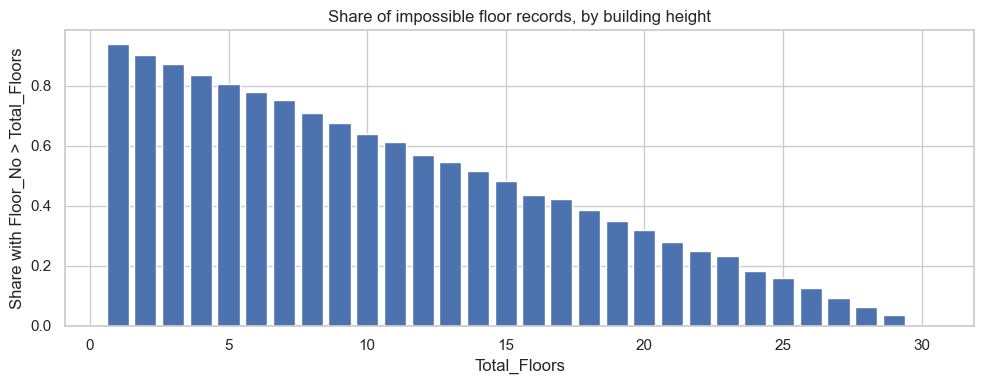

In [23]:
floor_values = np.arange(df_raw["Floor_No"].min(), df_raw["Floor_No"].max() + 1)
total_values = np.arange(df_raw["Total_Floors"].min(), df_raw["Total_Floors"].max() + 1)
expected_if_independent = (floor_values[:, None] > total_values[None, :]).mean()

print(f"Observed share of Floor_No > Total_Floors              : {floor_gt_total.mean():.4f}")
print(f"Expected if both were independent and evenly spread    : {expected_if_independent:.4f}")
rho = stats.spearmanr(df_raw["Floor_No"], df_raw["Total_Floors"])[0]
print(f"Spearman correlation between Floor_No and Total_Floors : {rho:.4f}")

share_by_total = floor_gt_total.groupby(df_raw["Total_Floors"]).mean()
plt.figure(figsize=(10, 4))
plt.bar(share_by_total.index, share_by_total.values, color="#4C72B0")
plt.xlabel("Total_Floors"); plt.ylabel("Share with Floor_No > Total_Floors")
plt.title("Share of impossible floor records, by building height")
save_fig("04_floor_inconsistency")

add_issue("Floor_No > Total_Floors (logically impossible)", n_bad,
          "KEEP rows; add flag column; exclude Floor_No/Total_Floors from model features (cannot be repaired)")
add_issue("Houses/Villas with Floor_No > 0", ((df_raw["Property_Type"] != "Apartment") & (df_raw["Floor_No"] > 0)).sum(),
          "KEEP; floor columns not trusted for non-apartments")

**Interpretation (based on the output above):** 
- **116,304 rows (46.52%)** have `Floor_No` above `Total_Floors`. Another 7,817 rows say the building has 1 floor but the property is above floor 1. These are logically impossible.
- The share is almost identical for apartments (46.58%), independent houses (46.40%) and villas (46.58%), and 161,644 houses and villas are placed on a floor above ground, which is also odd.
- If the two columns were generated **independently** and evenly spread, we would expect 46.77% of rows to be impossible. We observe 46.52%, and the correlation between the two columns is 0.0012 (essentially zero). The bar chart shows the share falling steadily as buildings get taller — exactly what two unrelated random numbers produce.
- **Treatment:** we cannot know which of the two numbers is wrong, so the rows cannot be repaired. Deleting 46.5% of the data would be unjustified. We **keep all rows, flag them** (Section 5.5), and recommend **not using the floor columns as model features**.

### 4.2 Price, size and price-per-sqft: are they consistent?
`Price_per_SqFt` should equal `Price_in_Lakhs ÷ Size_in_SqFt`. We recompute it (call it the **exact** value) and compare it with the stored column.

In [24]:
exact_ppsf = df_raw["Price_in_Lakhs"] / df_raw["Size_in_SqFt"]       # lakhs per sqft
reported_ppsf = df_raw["Price_per_SqFt"]

rounded_match = np.isclose(exact_ppsf.round(2), reported_ppsf, atol=1e-9)
print(f"Reported equals exact value rounded to 2 decimals : {rounded_match.mean() * 100:.4f}% of rows "
      f"({int((~rounded_match).sum())} rows differ)")
print(f"Largest absolute difference (exact vs reported)   : {(exact_ppsf - reported_ppsf).abs().max():.6f} lakhs/sqft")
print(f"Distinct values in the reported column            : {reported_ppsf.nunique()}")
print(f"Distinct values in the exact ratio                : {exact_ppsf.nunique():,}")
zero_reported = reported_ppsf == 0
print(f"Rows where reported Price_per_SqFt is exactly 0   : {int(zero_reported.sum()):,} ({zero_reported.mean() * 100:.2f}%)")
print(f"   ...of which the exact ratio is above 0         : {int((exact_ppsf[zero_reported] > 0).sum()):,}")
print()
print("Rows where the stored value is not the 2-decimal rounding of the exact ratio:")
display(df_raw.loc[~rounded_match, ["ID", "Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt"]].assign(exact=exact_ppsf[~rounded_match]).head(25))

Reported equals exact value rounded to 2 decimals : 99.9916% of rows (21 rows differ)
Largest absolute difference (exact vs reported)   : 0.005000 lakhs/sqft
Distinct values in the reported column            : 100
Distinct values in the exact ratio                : 249,267
Rows where reported Price_per_SqFt is exactly 0   : 2,534 (1.01%)
   ...of which the exact ratio is above 0         : 2,534

Rows where the stored value is not the 2-decimal rounding of the exact ratio:


,ID,Price_in_Lakhs,Size_in_SqFt,Price_per_SqFt,exact
3964,3965,69.6500,2786,0.0300,0.0250
16607,16608,382.2000,728,0.5300,0.5250
26681,26682,292.9500,558,0.5300,0.5250
30731,30732,239.5500,3194,0.0700,0.0750
52600,52601,448.8800,2896,0.1500,0.1550
75443,75444,217.7700,2562,0.0900,0.0850
75873,75874,15.5100,1034,0.0100,0.0150
85357,85358,385.2700,1306,0.2900,0.2950
88087,88088,23.4700,4694,0.0100,0.005000
99274,99275,231.8200,692,0.3300,0.3350


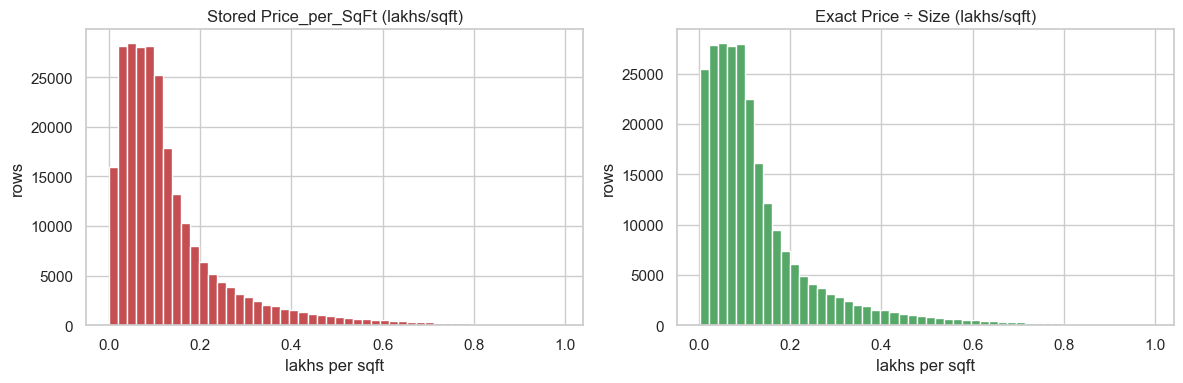

PASS ✅ - Price_per_SqFt = round(Price/Size, 2) for >99.9% of rows 


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(reported_ppsf, bins=50, color="#C44E52"); axes[0].set_title("Stored Price_per_SqFt (lakhs/sqft)")
axes[1].hist(exact_ppsf, bins=50, color="#55A868");   axes[1].set_title("Exact Price ÷ Size (lakhs/sqft)")
for ax in axes: ax.set_xlabel("lakhs per sqft"); ax.set_ylabel("rows")
save_fig("04_ppsf_reported_vs_exact")

check("Price_per_SqFt = round(Price/Size, 2) for >99.9% of rows", rounded_match.mean() > 0.999)
add_issue("Stored Price_per_SqFt rounded to 2 decimals (only 100 distinct values)", len(df_raw),
          "KEEP original; create exact Price_per_SqFt_exact = Price/Size and use that for analysis")
add_issue("Stored Price_per_SqFt equals 0 (rounding artifact)", zero_reported.sum(),
          "KEEP; replaced by exact ratio; flag column added")
add_issue("Stored Price_per_SqFt differs from round(Price/Size, 2)", (~rounded_match).sum(),
          "KEEP; negligible (rounding ties)")

**Interpretation (based on the output above):** 
- The stored `Price_per_SqFt` is `Price_in_Lakhs ÷ Size_in_SqFt` **rounded to 2 decimals** (lakhs per sq ft). It matches that rule in 99.9916% of rows; the 21 other rows are rounding ties (for example an exact value of 0.0250 stored as 0.03), and the largest difference is 0.005 lakh (₹500 per sq ft).
- Because of the rounding, the stored column has only **100 distinct values**, while the exact ratio has 249,267. This is a loss of detail.
- **2,534 rows (1.01%)** show a stored value of exactly 0 even though every one of them has a positive exact ratio. A zero price per sq ft would be wrong.
- **Treatment:** keep the original column untouched, and use the exact ratio (`Price_per_SqFt_exact`, added in Section 5.5) for all analysis.

### 4.3 Year built and property age
`Age_of_Property` should equal `reference year − Year_Built`. The reference year is not stated in the data, so we test several candidates and see which one fits.

In [26]:
rows = []
for ref_year in range(2020, 2031):
    share = ((ref_year - df_raw["Year_Built"]) == df_raw["Age_of_Property"]).mean()
    rows.append({"reference_year": ref_year, "share_of_rows_matching": share})
display(pd.DataFrame(rows))

print("Year_Built range :", df_raw["Year_Built"].min(), "to", df_raw["Year_Built"].max())
print("Age range        :", df_raw["Age_of_Property"].min(), "to", df_raw["Age_of_Property"].max())
print("Age + Year_Built (distinct sums):", (df_raw["Age_of_Property"] + df_raw["Year_Built"]).unique())
check("Age_of_Property = 2025 - Year_Built in every row",
      ((2025 - df_raw["Year_Built"]) == df_raw["Age_of_Property"]).all())

,reference_year,share_of_rows_matching
0,2020,0
1,2021,0
2,2022,0
3,2023,0
4,2024,0
5,2025,1.0000
6,2026,0
7,2027,0
8,2028,0
9,2029,0


Year_Built range : 1990 to 2023
Age range        : 2 to 35
Age + Year_Built (distinct sums): [2025]
PASS ✅ - Age_of_Property = 2025 - Year_Built in every row 


**Interpretation (based on the output above):** 
`Age_of_Property` equals **2025 − `Year_Built` in 100% of rows**; no other reference year matches any row, and `Age + Year_Built` is always 2025. So the two columns carry identical information (they are perfectly redundant). The minimum age is 2 because the newest build year is 2023. Note that **2025 is fixed inside the data**, not today's date, so ages are one year behind if calculated today. We keep the data's convention for consistency (an open item for Phase 3 if the app asks users for a build year).

### 4.4 Availability status versus build year
A property marked `Under_Construction` should not have a construction year in the past. Let's check.

In [27]:
uc = df_raw["Availability_Status"] == "Under_Construction"
print("Under_Construction rows:", f"{int(uc.sum()):,}", f"({uc.mean() * 100:.2f}%)")
print("Year_Built of Under_Construction rows: min", df_raw.loc[uc, "Year_Built"].min(), "max", df_raw.loc[uc, "Year_Built"].max())
print("Age of Under_Construction rows       : min", df_raw.loc[uc, "Age_of_Property"].min(), "max", df_raw.loc[uc, "Age_of_Property"].max())
print()
display(df_raw.groupby("Availability_Status")["Age_of_Property"].describe())
add_issue("Under_Construction properties with a past Year_Built (all have Year_Built <= 2023)", uc.sum(),
          "KEEP; do not use Availability_Status together with Age as if both were reliable; document")

Under_Construction rows: 125,035 (50.01%)
Year_Built of Under_Construction rows: min 1990 max 2023
Age of Under_Construction rows       : min 2 max 35



,count,mean,std,min,25%,50%,75%,max
Availability_Status,,,,,,,,
Ready_to_Move,"124,965.0",18.4771,9.7990,2.0000,10.0000,18.0000,27.0000,35.0000
Under_Construction,"125,035.0",18.4829,9.8182,2.0000,10.0000,18.0000,27.0000,35.0000


**Interpretation (based on the output above):** 
All **125,035 `Under_Construction` rows** (50.01%) have a construction year between 1990 and 2023 and an age of 2 to 35 years. An under-construction property cannot be 35 years old. In fact, the age distribution of the two statuses is the same (mean 18.48 vs 18.48 years, median 18 for both), so the status looks unrelated to the build year. **Treatment:** keep the column, but do not treat the combination of status and age as reliable; record it in the documentation.

### 4.5 BHK versus size
More bedrooms should usually mean a larger property. We test whether size rises with BHK and look for extreme combinations.

In [28]:
size_per_bhk = df_raw["Size_in_SqFt"] / df_raw["BHK"]
print("Median Size_in_SqFt by BHK:")
display(df_raw.groupby("BHK")["Size_in_SqFt"].agg(["count", "median", "min", "max"]))
print("Spearman correlation BHK vs Size:", round(stats.spearmanr(df_raw["BHK"], df_raw["Size_in_SqFt"])[0], 4))
print("Size per BHK (sqft) summary:")
print(size_per_bhk.describe().round(1).to_string())
small = size_per_bhk < 200
print(f"\nRows with under 200 sqft per BHK : {int(small.sum()):,}")
print(f"1-BHK with Size >= 4,000 sqft    : {int(((df_raw['BHK'] == 1) & (df_raw['Size_in_SqFt'] >= 4000)).sum()):,}")
print(f"5-BHK with Size <= 700 sqft      : {int(((df_raw['BHK'] == 5) & (df_raw['Size_in_SqFt'] <= 700)).sum()):,}")
add_issue("Under 200 sqft per BHK (implausibly cramped)", small.sum(),
          "KEEP; threshold is a judgement call; size_per_bhk derived for EDA only")

Median Size_in_SqFt by BHK:


,count,median,min,max
BHK,,,,
1,50196,"2,747.0",500,5000
2,49815,"2,746.0",500,5000
3,50067,"2,750.0",500,5000
4,49788,"2,755.0",500,5000
5,50134,"2,737.5",500,5000


Spearman correlation BHK vs Size: -0.001
Size per BHK (sqft) summary:
count   250,000.0
mean      1,257.0
std       1,065.1
min      100.0000
25%      542.0000
50%      918.0000
75%       1,563.5
max       5,000.0

Rows with under 200 sqft per BHK : 10,080
1-BHK with Size >= 4,000 sqft    : 11,139
5-BHK with Size <= 700 sqft      : 2,280


**Interpretation (based on the output above):** 
The median size is about the same for every BHK value (2,737.5 to 2,755 sq ft) and the rank correlation between BHK and size is −0.001, so **more bedrooms do not mean a bigger property in this data**. As a result, 10,080 rows (4.03%) have under 200 sq ft per BHK, 11,139 one-BHK properties are 4,000 sq ft or larger, and 2,280 five-BHK properties are 700 sq ft or smaller. The 200 sq ft threshold is a judgement call, so these rows are only counted, not removed.

### 4.6 Outliers: how we identify them
An **outlier** is a value far from the rest. We use the **IQR rule** (the same rule boxplots use):

1. Q1 = the 25th percentile, Q3 = the 75th percentile, IQR = Q3 − Q1.
2. A value below `Q1 − 1.5 × IQR` or above `Q3 + 1.5 × IQR` is flagged.

*A flagged value is not automatically an error.* It is only a value worth a closer look. We apply the rule to the numeric columns where a very high or low value would matter.

In [29]:
def iqr_table(series_dict):
    rows = []
    for name, s in series_dict.items():
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_low, n_high = int((s < low).sum()), int((s > high).sum())
        rows.append({"column": name, "Q1": q1, "Q3": q3, "lower_fence": low, "upper_fence": high,
                     "n_below": n_low, "n_above": n_high, "pct_flagged": round(100 * (n_low + n_high) / len(s), 2)})
    return pd.DataFrame(rows).set_index("column")

outlier_input = {
    "Size_in_SqFt": df_raw["Size_in_SqFt"],
    "Price_in_Lakhs": df_raw["Price_in_Lakhs"],
    "Price_per_SqFt (stored)": df_raw["Price_per_SqFt"],
    "Price_per_SqFt (exact)": exact_ppsf,
    "Nearby_Schools": df_raw["Nearby_Schools"],
    "Nearby_Hospitals": df_raw["Nearby_Hospitals"],
    "Age_of_Property": df_raw["Age_of_Property"],
    "Floor_No": df_raw["Floor_No"],
    "Total_Floors": df_raw["Total_Floors"],
}
outlier_table = iqr_table(outlier_input)
display(outlier_table)
n_out_stored = int(outlier_table.loc["Price_per_SqFt (stored)", ["n_below", "n_above"]].sum())
n_out_exact = int(outlier_table.loc["Price_per_SqFt (exact)", ["n_below", "n_above"]].sum())
add_issue("IQR outliers in stored Price_per_SqFt (all on the high side)", n_out_stored,
          "KEEP; they come from dividing by small sizes; analyse on a log scale; do not cap or delete")
add_issue("IQR outliers in exact Price/Size", n_out_exact, "KEEP; same reason")

,Q1,Q3,lower_fence,upper_fence,n_below,n_above,pct_flagged
column,,,,,,,
Size_in_SqFt,"1,623.0","3,874.0","-1,753.5","7,250.5",0,0,0
Price_in_Lakhs,132.5500,376.8800,-233.9450,743.3750,0,0,0
Price_per_SqFt (stored),0.0500,0.1600,-0.1150,0.3250,0,20020,8.0100
Price_per_SqFt (exact),0.0480,0.1599,-0.1197,0.3276,0,19723,7.8900
Nearby_Schools,3.0000,8.0000,-4.5000,15.5000,0,0,0
Nearby_Hospitals,3.0000,8.0000,-4.5000,15.5000,0,0,0
Age_of_Property,10.0000,27.0000,-15.5000,52.5000,0,0,0
Floor_No,7.0000,23.0000,-17.0000,47.0000,0,0,0
Total_Floors,8.0000,23.0000,-14.5000,45.5000,0,0,0


**Interpretation (based on the output above):** 
- `Size_in_SqFt` and `Price_in_Lakhs` have **0 outliers**: both are bounded (500 to 5,000 and 10 to 500) and the IQR fences (7,250.5 and 743.4) lie beyond the largest values. The other numeric columns also have 0.
- Price per sq ft is the only column with flagged values, all on the **high** side: **20,020 rows (8.01%)** for the stored column and **19,723 rows (7.89%)** for the exact ratio. Phase 1 reported the first figure; the second is the one we will use.
- A flagged value is a *candidate*, not proof of an error. Section 5.6 investigates why they occur before any decision is made.

### 4.7 Summary of the data-quality log
This table is our *investigation record*. It is saved at the end as `data_quality_report.csv`.

In [30]:
quality_report = pd.DataFrame(quality_rows)
display(quality_report)

,issue,rows_affected,pct_of_rows,proposed_treatment
0,Floor_No > Total_Floors (logically impossible),116304,46.5200,KEEP rows; add flag column; exclude Floor_No/Total_Floors from model features (cannot be repaired)
1,Houses/Villas with Floor_No > 0,161644,64.6600,KEEP; floor columns not trusted for non-apartments
2,Stored Price_per_SqFt rounded to 2 decimals (only 100 distinct values),250000,100.0000,KEEP original; create exact Price_per_SqFt_exact = Price/Size and use that for analysis
3,Stored Price_per_SqFt equals 0 (rounding artifact),2534,1.0100,KEEP; replaced by exact ratio; flag column added
4,"Stored Price_per_SqFt differs from round(Price/Size, 2)",21,0.0100,KEEP; negligible (rounding ties)
5,Under_Construction properties with a past Year_Built (all have Year_Built <= 2023),125035,50.0100,KEEP; do not use Availability_Status together with Age as if both were reliable; document
6,Under 200 sqft per BHK (implausibly cramped),10080,4.0300,KEEP; threshold is a judgement call; size_per_bhk derived for EDA only
7,IQR outliers in stored Price_per_SqFt (all on the high side),20020,8.0100,KEEP; they come from dividing by small sizes; analyse on a log scale; do not cap or delete
8,IQR outliers in exact Price/Size,19723,7.8900,KEEP; same reason


## 5. Data cleaning

**Principles**
1. The original `df_raw` stays untouched. We work on a copy called `df_clean`.
2. We only apply a correction when the data *proves* it is needed.
3. Suspicious-but-possible records are **flagged, not deleted**.
4. We report the row count before and after.

Each sub-step below records what it did in a `cleaning_log`.

In [31]:
df_clean = df_raw.copy()          # a separate copy; df_raw is never changed
rows_before = len(df_clean)
cleaning_log = []

def log_step(step, action, rows_changed):
    cleaning_log.append({"step": step, "action": action, "rows_changed": int(rows_changed)})
    print(f"[{step}] {action} (rows changed: {int(rows_changed):,})")

print("Rows before cleaning:", f"{rows_before:,}")

Rows before cleaning: 250,000


### 5.1 Remove stray spaces in text columns
Extra spaces (e.g. `"Mumbai "` vs `"Mumbai"`) would make one category look like two. We strip them and count how many cells changed.

In [32]:
changed_cells = 0
for col in categorical_cols:
    stripped = df_clean[col].str.strip()
    changed_cells += int((stripped != df_clean[col]).sum())
    df_clean[col] = stripped
log_step("5.1", "Stripped leading/trailing spaces in all text columns", changed_cells)

[5.1] Stripped leading/trailing spaces in all text columns (rows changed: 0)


### 5.2 Missing values
Section 3.5 found none. The code below shows what we *would* do if there were some (median for numbers, most common value for text), so you can reuse it on other data.

In [33]:
total_missing = int(df_clean.isna().sum().sum())
if total_missing == 0:
    log_step("5.2", "No missing values found - no imputation needed", 0)
else:
    for col in df_clean.columns[df_clean.isna().any()]:
        if col in numeric_cols:
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())
        else:
            df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])
    log_step("5.2", "Filled missing values (median / mode)", total_missing)
assert df_clean.isna().sum().sum() == 0

[5.2] No missing values found - no imputation needed (rows changed: 0)


### 5.3 Duplicates
Section 3.6 found none. We drop duplicates only if they exist.

In [34]:
n_dup = int(df_clean.duplicated().sum())
if n_dup > 0:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)
log_step("5.3", "Dropped fully duplicated rows" if n_dup else "No duplicate rows found - nothing dropped", n_dup)
assert df_clean["ID"].is_unique

[5.3] No duplicate rows found - nothing dropped (rows changed: 0)


### 5.4 Standardising category names
We print every value of the small categorical columns. We rename only if the *same* thing is spelled two ways (e.g. `"Semi"` and `"Semi-furnished"`).

In [35]:
for col in ["Property_Type", "Furnished_Status", "Public_Transport_Accessibility", "Parking_Space", "Security",
            "Facing", "Owner_Type", "Availability_Status"]:
    print(f"{col:32s}", sorted(df_clean[col].unique()))
log_step("5.4", "Checked category spellings - no duplicates in spelling, no renaming required", 0)

Property_Type                    ['Apartment', 'Independent House', 'Villa']
Furnished_Status                 ['Furnished', 'Semi-furnished', 'Unfurnished']
Public_Transport_Accessibility   ['High', 'Low', 'Medium']
Parking_Space                    ['No', 'Yes']
Security                         ['No', 'Yes']
Facing                           ['East', 'North', 'South', 'West']
Owner_Type                       ['Broker', 'Builder', 'Owner']
Availability_Status              ['Ready_to_Move', 'Under_Construction']
[5.4] Checked category spellings - no duplicates in spelling, no renaming required (rows changed: 0)


**Interpretation (based on the output above):** 
The text columns are clean: no stray spaces were found, and no category is spelled two ways, so **no renaming is needed**. Note three differences from the project PDF, which we record but do **not** "fix": `Furnished_Status` uses *Semi-furnished* (PDF: Semi / Fully), `Owner_Type` uses *Owner / Broker / Builder* (PDF: Individual / Builder / Agent), and `Availability_Status` has only *Ready_to_Move* and *Under_Construction* (the PDF also lists Sold). Mapping, for example, *Broker* to *Agent* would be an assumption, so we keep the dataset's own labels.

### 5.5 Justified additions: the exact price per sqft and two quality flags
These are the only new columns added during cleaning. We **keep the original `Price_per_SqFt`** and add:

| New column | Why |
|---|---|
| `Price_per_SqFt_exact` | `Price_in_Lakhs ÷ Size_in_SqFt` without rounding. Fixes the 2-decimal rounding problem found in 4.2. |
| `flag_floor_gt_total` | `True` where `Floor_No > Total_Floors`. Marks the impossible rows without deleting them. |
| `flag_stored_ppsf_zero` | `True` where the stored price per sqft is 0 (a rounding artifact). |

In [36]:
df_clean["Price_per_SqFt_exact"] = df_clean["Price_in_Lakhs"] / df_clean["Size_in_SqFt"]
df_clean["flag_floor_gt_total"] = df_clean["Floor_No"] > df_clean["Total_Floors"]
df_clean["flag_stored_ppsf_zero"] = df_clean["Price_per_SqFt"] == 0

log_step("5.5", "Added Price_per_SqFt_exact (original column kept)", len(df_clean))
log_step("5.5", "Added flag_floor_gt_total", df_clean["flag_floor_gt_total"].sum())
log_step("5.5", "Added flag_stored_ppsf_zero", df_clean["flag_stored_ppsf_zero"].sum())

assert (df_clean["Price_per_SqFt_exact"] > 0).all()
assert np.isclose(df_clean["Price_per_SqFt_exact"].round(2), df_clean["Price_per_SqFt"], atol=1e-9).mean() > 0.999

[5.5] Added Price_per_SqFt_exact (original column kept) (rows changed: 250,000)
[5.5] Added flag_floor_gt_total (rows changed: 116,304)
[5.5] Added flag_stored_ppsf_zero (rows changed: 2,534)


### 5.6 Outliers: investigate, then decide
From 4.6: `Size_in_SqFt` and `Price_in_Lakhs` have no IQR outliers. The only flagged values are in price per sqft. Let's check *why* before deciding anything.

In [37]:
ppsf = df_clean["Price_per_SqFt_exact"]
q1, q3 = ppsf.quantile([0.25, 0.75]); fence = q3 + 1.5 * (q3 - q1)
is_out = ppsf > fence
print(f"Upper fence for exact price/sqft: {fence:.4f} lakhs/sqft")
print(f"Flagged rows: {int(is_out.sum()):,} ({is_out.mean() * 100:.2f}%)")
print()
print("Size_in_SqFt   - flagged rows vs all rows (median):", df_clean.loc[is_out, "Size_in_SqFt"].median(), "vs", df_clean["Size_in_SqFt"].median())
print("Price_in_Lakhs - flagged rows vs all rows (median):", round(df_clean.loc[is_out, "Price_in_Lakhs"].median(), 1), "vs", round(df_clean["Price_in_Lakhs"].median(), 1))
print("Largest size among flagged rows:", df_clean.loc[is_out, "Size_in_SqFt"].max())
print("Price_in_Lakhs range among flagged rows:", df_clean.loc[is_out, "Price_in_Lakhs"].min(), "to", df_clean.loc[is_out, "Price_in_Lakhs"].max())
log_step("5.6", "Investigated price/sqft outliers - kept all rows (they are arithmetic results of small sizes, not errors)", 0)

Upper fence for exact price/sqft: 0.3276 lakhs/sqft
Flagged rows: 19,723 (7.89%)

Size_in_SqFt   - flagged rows vs all rows (median): 799.0 vs 2747.0
Price_in_Lakhs - flagged rows vs all rows (median): 400.9 vs 253.9
Largest size among flagged rows: 1515
Price_in_Lakhs range among flagged rows: 165.08 to 499.99
[5.6] Investigated price/sqft outliers - kept all rows (they are arithmetic results of small sizes, not errors) (rows changed: 0)


**Interpretation (based on the output above):** 
The flagged rows are **19,723 (7.89%)**, all with a price per sq ft above ₹32,764. They are mostly small properties: the median size of flagged rows is 799 sq ft (against 2,747 overall), 74.0% are under 1,000 sq ft and none exceeds 1,515 sq ft, while their prices range from 165 to 500 lakhs. In other words, they are what you get when a high price is divided by a small size — the arithmetic result of the data's own definition, not typing mistakes. Section Q4 shows that price and size are unrelated in this dataset, which is why such combinations occur.

**Decision:** keep every row, do not cap or delete. Use a log scale in charts. Any model that is sensitive to skew can use a transformed version in Phase 3.

### 5.7 Rows before and after cleaning, and proof the original is untouched

In [38]:
rows_after = len(df_clean)
print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning : {rows_after:,}")
print(f"Rows removed        : {rows_before - rows_after:,}")
print(f"Columns before/after: {df_raw.shape[1]} -> {df_clean.shape[1]}  (3 columns added, none changed or removed)")

assert rows_after == rows_before == 250_000
original_reloaded = pd.read_csv(DATA_PATH)
check("Original data unchanged (df_raw equals a fresh reload of the CSV)", df_raw.equals(original_reloaded))
check("Original 23 columns unchanged inside df_clean", df_clean[EXPECTED_COLUMNS].equals(df_raw[EXPECTED_COLUMNS]))
del original_reloaded

cleaning_log_df = pd.DataFrame(cleaning_log)
display(cleaning_log_df)

Rows before cleaning: 250,000
Rows after cleaning : 250,000
Rows removed        : 0
Columns before/after: 23 -> 26  (3 columns added, none changed or removed)
PASS ✅ - Original data unchanged (df_raw equals a fresh reload of the CSV) 
PASS ✅ - Original 23 columns unchanged inside df_clean 


,step,action,rows_changed
0,5.1,Stripped leading/trailing spaces in all text columns,0
1,5.2,No missing values found - no imputation needed,0
2,5.3,No duplicate rows found - nothing dropped,0
3,5.4,"Checked category spellings - no duplicates in spelling, no renaming required",0
4,5.5,Added Price_per_SqFt_exact (original column kept),250000
5,5.5,Added flag_floor_gt_total,116304
6,5.5,Added flag_stored_ppsf_zero,2534
7,5.6,"Investigated price/sqft outliers - kept all rows (they are arithmetic results of small sizes, not errors)",0


**Interpretation (based on the output above):** 
**250,000 rows before and 250,000 after: nothing was removed**, because the checks found no missing values, no duplicates, no spelling problems and no value that could be proven wrong. The only changes are **three added columns** (`Price_per_SqFt_exact`, `flag_floor_gt_total`, `flag_stored_ppsf_zero`); the original 23 columns are identical to the file, and the PASS messages confirm that the raw data was not modified. In this dataset "cleaning" therefore meant *verifying and annotating*, not deleting.

## 6. Feature engineering

A **feature** is an input column a model can use. We create new ones only when they can be calculated **reliably from the data we actually have**. We also watch for two dangers:

- **Redundancy** — two columns that carry the same information (e.g. `Year_Built` and `Age_of_Property`).
- **Data leakage** — a feature that secretly contains the answer. Example: `Price_per_SqFt` is simply `Price ÷ Size`, so a model predicting *price* must never be given it.

We build on a copy: `df_feat = df_clean.copy()`.

In [39]:
df_feat = df_clean.copy()
print("Starting feature table:", df_feat.shape)

Starting feature table: (250000, 26)


### 6.1 Price per square foot
We already added `Price_per_SqFt_exact` (lakhs per sqft). For readable charts we also express it in **rupees per sqft**.

> **Assumption (flag):** the PDF only says "local currency". We assume 1 lakh = 100,000 and the currency is rupees, as the column name `Price_in_Lakhs` and the Indian state names suggest. If the currency were different, only the label in the charts would change.

In [40]:
df_feat["Price_per_SqFt_INR"] = df_feat["Price_per_SqFt_exact"] * 100_000
print(df_feat["Price_per_SqFt_INR"].describe().round(0).to_string())

count   250,000.0
mean     13,058.0
std      13,072.0
min      202.0000
25%       4,803.0
50%       9,245.0
75%      15,987.0
max      99,182.0


### 6.2 Property age
`Age_of_Property` already equals `2025 − Year_Built` in every row (Section 4.3). Recomputing it would add nothing, and `Year_Built` and `Age_of_Property` are perfectly redundant — so **no new age feature is created**. We keep `Age_of_Property` for modelling and `Year_Built` for EDA only.

### 6.3 Floor-related features
`Floor_No` and `Total_Floors` contradict each other in about 46.5% of rows, so a ratio such as `Floor_No ÷ Total_Floors` would be above 1 for nearly half the data. Let us confirm that, then **decide not to create it**.

In [41]:
temp_ratio = df_feat["Floor_No"] / df_feat["Total_Floors"]          # temporary, NOT saved
print(f"Floor ratio above 1 (impossible): {(temp_ratio > 1).mean() * 100:.2f}% of rows")
print(temp_ratio.describe().round(3).to_string())
del temp_ratio
print("\nDecision: no floor-ratio feature. The existing flag_floor_gt_total column is kept for EDA.")

Floor ratio above 1 (impossible): 46.52% of rows
count   250,000.0
mean       1.9950
std        3.5190
min             0
25%        0.4670
50%        0.9640
75%        1.8890
max       30.0000

Decision: no floor-ratio feature. The existing flag_floor_gt_total column is kept for EDA.


### 6.4 Amenities → five yes/no columns plus a count
A model cannot read `"Pool, Gym"`. We split the text into one 0/1 column per amenity and add `Amenity_Count`.

In [42]:
amenity_sets = df_feat["Amenities"].str.split(",").apply(lambda items: {a.strip() for a in items})
AMENITY_NAMES = sorted({a for s in amenity_sets for a in s})
for name in AMENITY_NAMES:
    df_feat[f"Has_{name}"] = amenity_sets.apply(lambda s, n=name: int(n in s))
df_feat["Amenity_Count"] = amenity_sets.apply(len)

amenity_flag_cols = [f"Has_{n}" for n in AMENITY_NAMES]
print("New columns:", amenity_flag_cols + ["Amenity_Count"])
assert (df_feat[amenity_flag_cols].sum(axis=1) == df_feat["Amenity_Count"]).all()
assert df_feat["Amenity_Count"].between(1, 5).all()
print("Check passed: flags add up to Amenity_Count in every row.")
display(df_feat[["Amenities"] + amenity_flag_cols + ["Amenity_Count"]].head())
print("Share of properties offering each amenity:")
print(df_feat[amenity_flag_cols].mean().round(4).to_string())

New columns: ['Has_Clubhouse', 'Has_Garden', 'Has_Gym', 'Has_Playground', 'Has_Pool', 'Amenity_Count']
Check passed: flags add up to Amenity_Count in every row.


,Amenities,Has_Clubhouse,Has_Garden,Has_Gym,Has_Playground,Has_Pool,Amenity_Count
0,"Playground, Gym, Garden, Pool, Clubhouse",1,1,1,1,1,5
1,"Playground, Clubhouse, Pool, Gym, Garden",1,1,1,1,1,5
2,"Clubhouse, Pool, Playground, Gym",1,0,1,1,1,4
3,"Playground, Clubhouse, Gym, Pool, Garden",1,1,1,1,1,5
4,"Playground, Garden, Gym, Pool, Clubhouse",1,1,1,1,1,5


Share of properties offering each amenity:
Has_Clubhouse    0.6002
Has_Garden       0.6007
Has_Gym          0.5998
Has_Playground   0.5991
Has_Pool         0.6004


### 6.5 Transport level and a simple infrastructure score
`Public_Transport_Accessibility` is **ordered** (Low < Medium < High), so we turn it into 0 / 1 / 2.

For the spec's "infrastructure score" we follow the Phase 1 definition:

`Infra_Score = Nearby_Schools + Nearby_Hospitals + Transport_Level`   (range 2 to 22)

> **Flag — this is our own index, not a measured quantity.** It weights schools and hospitals (each 1–10) much more than transport (0–2). It is used for *description* only; the weighting is an open decision for Phase 3.
>
> **"School Density Score" is not created:** density needs an area or population, and the dataset has neither. `Nearby_Schools` is just a 1–10 count/rating.

In [43]:
transport_map = {"Low": 0, "Medium": 1, "High": 2}
df_feat["Transport_Level"] = df_feat["Public_Transport_Accessibility"].map(transport_map)
assert df_feat["Transport_Level"].notna().all(), "Unexpected transport category found"

df_feat["Infra_Score"] = df_feat["Nearby_Schools"] + df_feat["Nearby_Hospitals"] + df_feat["Transport_Level"]
print(df_feat["Infra_Score"].describe().round(2).to_string())
assert df_feat["Infra_Score"].between(2, 22).all()

count   250,000.0
mean      12.0000
std        4.1400
min        2.0000
25%        9.0000
50%       12.0000
75%       15.0000
max       22.0000


### 6.6 Size per BHK (data-quality / EDA helper only)
`Size_per_BHK = Size_in_SqFt ÷ BHK`. It is *not* meant for modelling (it is derived from two other columns); it simply helps describe how roomy the listings are.

In [44]:
df_feat["Size_per_BHK"] = df_feat["Size_in_SqFt"] / df_feat["BHK"]
print(df_feat["Size_per_BHK"].describe().round(1).to_string())

count   250,000.0
mean      1,257.0
std       1,065.1
min      100.0000
25%      542.0000
50%      918.0000
75%       1,563.5
max       5,000.0


### 6.7 Location-level price summaries (kept as **separate tables**)
It is tempting to add a column such as *"average price in this city"* to every row. **We deliberately do not.** If a property's own price is part of its city average, the model would be given a blurred copy of the answer — a form of **target leakage** (and the leak gets worse in small groups). If such an encoding is needed in Phase 3, it must be computed on the **training set only**.

Instead we create summary tables for EDA and for the future app's charts.

In [45]:
def location_summary(group_col):
    g = df_feat.groupby(group_col)
    out = pd.DataFrame({
        "properties": g.size(),
        "mean_price_lakhs": g["Price_in_Lakhs"].mean(),
        "median_price_lakhs": g["Price_in_Lakhs"].median(),
        "mean_ppsf_inr": g["Price_per_SqFt_INR"].mean(),
        "median_ppsf_inr": g["Price_per_SqFt_INR"].median(),
        "median_age_years": g["Age_of_Property"].median(),
    })
    return out.sort_values("median_price_lakhs", ascending=False)

state_summary = location_summary("State")
city_summary = location_summary("City")
locality_summary = location_summary("Locality")
print("State summary:", state_summary.shape, "| City summary:", city_summary.shape, "| Locality summary:", locality_summary.shape)
display(city_summary.head(5))

State summary: (20, 6) | City summary: (42, 6) | Locality summary: (500, 6)


,properties,mean_price_lakhs,median_price_lakhs,mean_ppsf_inr,median_ppsf_inr,median_age_years
City,,,,,,
Mysore,4217,256.8482,259.5200,"13,244.3","9,271.9",19.0000
Pune,4224,256.4957,258.9300,"13,294.8","9,538.7",18.0000
Kochi,6305,257.4152,258.7500,"13,202.7","9,280.6",18.0000
Bangalore,4144,258.4566,258.3600,"13,139.5","9,344.1",18.0000
Bhopal,6284,256.4989,258.2300,"12,959.1","9,236.2",18.0000


### 6.8 Feature decisions (carried over from the Phase 1 handoff)
This dictionary is saved as `feature_dictionary.csv` and is the input list for Phase 3.

In [46]:
feature_dictionary = pd.DataFrame([
    ("ID", "original", "EXCLUDE", "Identifier only"),
    ("State", "original", "EDA only", "City already determines State (redundant)"),
    ("City", "original", "RETAIN", "42 levels; one-hot encode later"),
    ("Locality", "original", "EDA only", "500 labels repeated in every city; no geographic meaning"),
    ("Property_Type", "original", "RETAIN", ""),
    ("BHK", "original", "RETAIN", "Not for classification label-defining use (see Section 8)"),
    ("Size_in_SqFt", "original", "RETAIN", "Mechanically linked to price per sqft"),
    ("Price_in_Lakhs", "original", "TARGET BASIS / EXCLUDE from features", "Both targets would be built from it -> leakage if used as input"),
    ("Price_per_SqFt", "original", "EXCLUDE", "Rounded (100 values), 1.01% zeros; derived from Price/Size"),
    ("Price_per_SqFt_exact", "derived (cleaning)", "EDA / label construction only", "Price/Size; leaks the price if used as a feature"),
    ("Price_per_SqFt_INR", "derived", "EDA only", "exact value x 100,000 (assumes rupees)"),
    ("Year_Built", "original", "EDA only", "Redundant with Age_of_Property"),
    ("Age_of_Property", "original", "RETAIN", "= 2025 - Year_Built (reference year 2025)"),
    ("Furnished_Status", "original", "RETAIN", ""),
    ("Floor_No", "original", "EXCLUDE from features", "Contradicts Total_Floors in ~46.5% of rows"),
    ("Total_Floors", "original", "EXCLUDE from features", "As above"),
    ("flag_floor_gt_total", "derived (cleaning)", "EDA / documentation", "Marks impossible floor records"),
    ("flag_stored_ppsf_zero", "derived (cleaning)", "EDA / documentation", "Marks rounding-to-zero rows"),
    ("Nearby_Schools", "original", "RETAIN", "1-10 count/rating"),
    ("Nearby_Hospitals", "original", "RETAIN", "1-10 count/rating"),
    ("Public_Transport_Accessibility", "original", "RETAIN", "Ordinal Low<Medium<High"),
    ("Transport_Level", "derived", "RETAIN (encoded form)", "0/1/2 version of the column above"),
    ("Parking_Space", "original", "RETAIN", "Yes/No"),
    ("Security", "original", "RETAIN", "Yes/No"),
    ("Amenities", "original", "EXCLUDE raw text", "Replaced by the Has_* flags and Amenity_Count"),
    ("Has_<amenity> x5", "derived", "RETAIN", "Clubhouse, Garden, Gym, Playground, Pool"),
    ("Amenity_Count", "derived", "RETAIN", "Number of amenities (1-5)"),
    ("Facing", "original", "RETAIN", ""),
    ("Owner_Type", "original", "RETAIN", ""),
    ("Availability_Status", "original", "RETAIN (caution)", "Contradicts Year_Built for Under_Construction rows"),
    ("Infra_Score", "derived", "EDA; optional feature", "Schools + Hospitals + Transport_Level; our own index"),
    ("Size_per_BHK", "derived", "EDA only", "Size / BHK"),
], columns=["feature", "origin", "decision", "reason"])
display(feature_dictionary)
print("Final feature table shape:", df_feat.shape)

,feature,origin,decision,reason
0,ID,original,EXCLUDE,Identifier only
1,State,original,EDA only,City already determines State (redundant)
2,City,original,RETAIN,42 levels; one-hot encode later
3,Locality,original,EDA only,500 labels repeated in every city; no geographic meaning
4,Property_Type,original,RETAIN,
5,BHK,original,RETAIN,Not for classification label-defining use (see Section 8)
6,Size_in_SqFt,original,RETAIN,Mechanically linked to price per sqft
7,Price_in_Lakhs,original,TARGET BASIS / EXCLUDE from features,Both targets would be built from it -> leakage if used as input
8,Price_per_SqFt,original,EXCLUDE,"Rounded (100 values), 1.01% zeros; derived from Price/Size"
9,Price_per_SqFt_exact,derived (cleaning),EDA / label construction only,Price/Size; leaks the price if used as a feature


Final feature table shape: (250000, 36)


**Interpretation (based on the output above):** 
- **Created (10 columns, table now 250,000 × 36):** `Price_per_SqFt_INR`, five `Has_<amenity>` flags, `Amenity_Count`, `Transport_Level`, `Infra_Score`, `Size_per_BHK`, on top of the 3 cleaning columns.
- **Deliberately not created:** a new age feature (redundant), a floor ratio (unreliable for 46.5% of rows), a School Density Score (no area or population data), and location averages inside the row-level table (leakage risk).
- `Infra_Score` is our own simple index (range 2 to 22) and weights schools and hospitals more than transport; treat it as descriptive.
- Features that would leak the answer if used as model inputs are labelled in the dictionary (`Price_in_Lakhs`, `Price_per_SqFt`, `Price_per_SqFt_exact`).

## 7. Exploratory Data Analysis — the 20 official questions

### How to read the statistics in this section
- **Mean / median:** the average, and the middle value (the median is not pulled by extreme values).
- **95% confidence interval (CI):** a range that the true group average very likely lies in. Two groups whose CIs overlap heavily are **not clearly different**.
- **p-value:** the probability of seeing a difference this large *if there were truly no difference*. A tiny p-value says "unlikely to be chance".  
  **Caution:** with 250,000 rows even a trivial difference can get a tiny p-value, so we always also look at the **size** of the difference (effect size).
- **Correlation (r):** from −1 to +1. Values near 0 mean "no linear relationship"; |r| above 0.5 is strong.
- **Eta squared (η²):** the share of variation in a number that is explained by a category (0 = nothing, 1 = everything).

We analyse the engineered table `df_feat` and report price per sqft in **rupees per sqft** (`Price_per_SqFt_INR`) for readability. Prices stay in **lakhs** (1 lakh = 100,000 rupees).

In [47]:
eda = df_feat            # the table used for all questions below
PPSF = "Price_per_SqFt_INR"

def group_table(data, group_col, value_col):
    """Count, mean, median, std and 95% CI of the mean for each group."""
    t = data.groupby(group_col, observed=True)[value_col].agg(["count", "mean", "median", "std"])
    t["ci95_half_width"] = 1.96 * t["std"] / np.sqrt(t["count"])
    return t

def eta_squared(data, group_col, value_col):
    """Share of variance in value_col explained by group_col."""
    g = data.groupby(group_col, observed=True)[value_col]
    between = (g.count() * (g.mean() - data[value_col].mean()) ** 2).sum()
    total = ((data[value_col] - data[value_col].mean()) ** 2).sum()
    return between / total

def kruskal_p(data, group_col, value_col):
    groups = [g.values for _, g in data.groupby(group_col, observed=True)[value_col]]
    return stats.kruskal(*groups).pvalue

print("EDA helpers ready. Rows available:", f"{len(eda):,}")

EDA helpers ready. Rows available: 250,000


---
# Questions 1–5: Price & Size Analysis

## Q1. What is the distribution of property prices?

count   250,000.0
mean     254.5900
std      141.3500
min       10.0000
25%      132.5500
50%      253.8700
75%      376.8800
max      500.0000

Skewness: 0.008   (0 = symmetric)
Excess kurtosis: -1.199   (about -1.2 for an evenly spread, flat distribution)

With 20 equal-width price bins: smallest bin = 12,324 properties, largest bin = 12,865 (largest/smallest = 1.044)


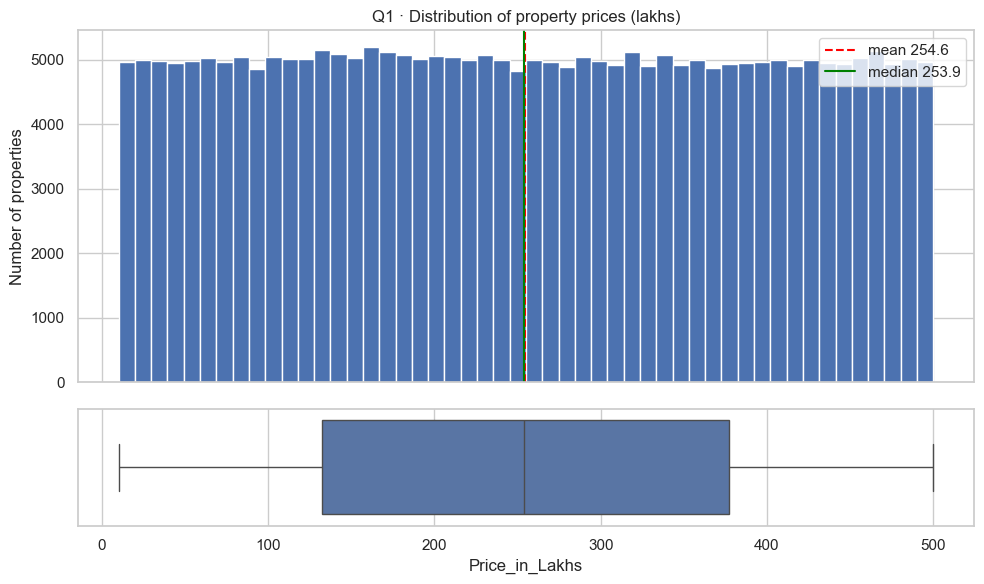

In [48]:
price = eda["Price_in_Lakhs"]
print(price.describe().round(2).to_string())
print(f"\nSkewness: {price.skew():.3f}   (0 = symmetric)")
print(f"Excess kurtosis: {price.kurt():.3f}   (about -1.2 for an evenly spread, flat distribution)")

counts, edges = np.histogram(price, bins=20)
print(f"\nWith 20 equal-width price bins: smallest bin = {counts.min():,} properties, largest bin = {counts.max():,} "
      f"(largest/smallest = {counts.max() / counts.min():.3f})")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
axes[0].hist(price, bins=50, color="#4C72B0", edgecolor="white")
axes[0].axvline(price.mean(), color="red", linestyle="--", label=f"mean {price.mean():.1f}")
axes[0].axvline(price.median(), color="green", linestyle="-", label=f"median {price.median():.1f}")
axes[0].set_ylabel("Number of properties"); axes[0].set_title("Q1 · Distribution of property prices (lakhs)"); axes[0].legend()
sns.boxplot(x=price, ax=axes[1], color="#4C72B0"); axes[1].set_xlabel("Price_in_Lakhs")
save_fig("q01_price_distribution")

**Interpretation (based on the output above):** 
Prices run from 10 to 500 lakhs with a mean of 254.59 and a median of 253.87 (almost equal). The skewness is 0.008 and the excess kurtosis is −1.199, which is what a **flat, evenly spread** distribution gives (about −1.2). Across 20 equal bins the smallest holds 12,324 properties and the largest 12,865 (ratio 1.04). So prices are spread almost evenly between 10 and 500 lakhs, with no long tail of very expensive properties and no outliers in the boxplot. Real housing prices are usually right-skewed, so this shape is unusual.

## Q2. What is the distribution of property sizes?

count   250,000.0
mean      2,749.8
std       1,300.6
min      500.0000
25%       1,623.0
50%       2,747.0
75%       3,874.0
max       5,000.0

Skewness: 0.001   Excess kurtosis: -1.200
With 20 equal-width size bins: smallest = 12,283, largest = 12,679 (ratio 1.032)


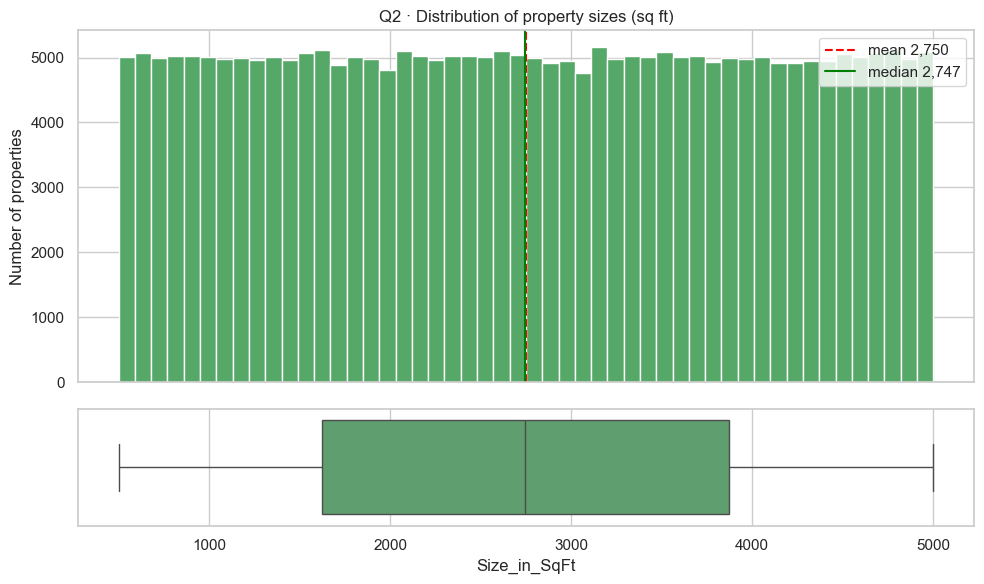

In [49]:
size = eda["Size_in_SqFt"]
print(size.describe().round(1).to_string())
print(f"\nSkewness: {size.skew():.3f}   Excess kurtosis: {size.kurt():.3f}")
counts, edges = np.histogram(size, bins=20)
print(f"With 20 equal-width size bins: smallest = {counts.min():,}, largest = {counts.max():,} (ratio {counts.max() / counts.min():.3f})")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
axes[0].hist(size, bins=50, color="#55A868", edgecolor="white")
axes[0].axvline(size.mean(), color="red", linestyle="--", label=f"mean {size.mean():,.0f}")
axes[0].axvline(size.median(), color="green", label=f"median {size.median():,.0f}")
axes[0].set_ylabel("Number of properties"); axes[0].set_title("Q2 · Distribution of property sizes (sq ft)"); axes[0].legend()
sns.boxplot(x=size, ax=axes[1], color="#55A868"); axes[1].set_xlabel("Size_in_SqFt")
save_fig("q02_size_distribution")

**Interpretation (based on the output above):** 
Sizes run from 500 to 5,000 sq ft, with a mean of 2,749.8 and a median of 2,747. Skewness is 0.001 and excess kurtosis −1.200, so, like price, size is **evenly spread** across its range (the 20 bins hold between 12,283 and 12,679 properties). There are no outliers.

## Q3. How does price per sq ft vary by property type?

,count,mean,median,std,ci95_half_width
Property_Type,,,,,
Apartment,82956,"13,047.0","9,245.0","13,063.0",89.0000
Independent House,83300,"13,102.0","9,305.0","13,045.0",89.0000
Villa,83744,"13,026.0","9,190.0","13,107.0",89.0000


Kruskal-Wallis test p-value (are the groups different?): 0.0186
Eta squared (share of price/sqft variation explained by property type): 0.000006


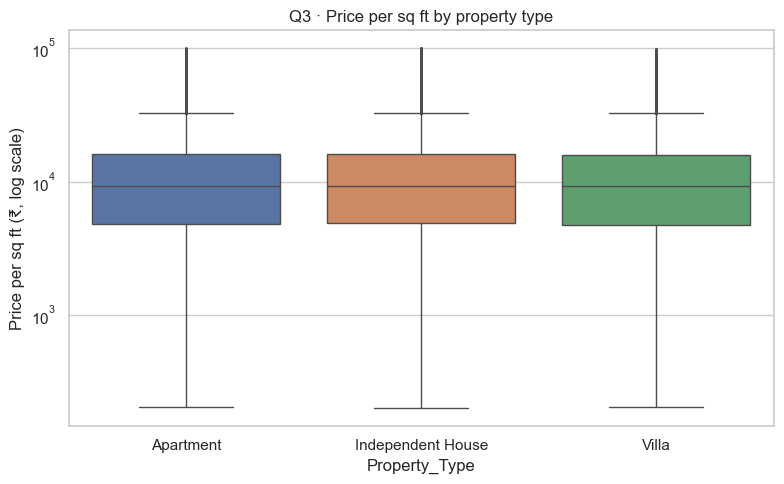

In [50]:
t3 = group_table(eda, "Property_Type", PPSF)
display(t3.round(0))
print("Kruskal-Wallis test p-value (are the groups different?):", f"{kruskal_p(eda, 'Property_Type', PPSF):.4f}")
print("Eta squared (share of price/sqft variation explained by property type):", f"{eta_squared(eda, 'Property_Type', PPSF):.6f}")

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=eda, x="Property_Type", y=PPSF, hue="Property_Type", legend=False, fliersize=1, ax=ax)
ax.set_yscale("log"); ax.set_ylabel("Price per sq ft (₹, log scale)"); ax.set_title("Q3 · Price per sq ft by property type")
save_fig("q03_ppsf_by_property_type")

**Interpretation (based on the output above):** 
Median price per sq ft is ₹9,245 for apartments, ₹9,305 for independent houses and ₹9,190 for villas (means ₹13,047, ₹13,102 and ₹13,026). The means differ by about ₹76, or 0.6% of the overall mean, and each group's 95% interval is about ±₹89, so the intervals overlap. The Kruskal-Wallis p-value of 0.0186 is formally below 0.05, but property type explains only 0.0006% of the variation (η² = 0.000006): a negligible difference that large samples can make look "significant". When many tests are run an occasional p-value below 0.05 is also expected by luck. **Conclusion: price per sq ft does not meaningfully differ by property type.** (The mean is far above the median because price per sq ft is right-skewed.)

## Q4. Is there a relationship between property size and price?

Pearson r  = -0.0025 (p = 0.206)
Spearman r = -0.0025 (p = 0.206)


,median,mean
499-947,257.4000,255.9000
947-1398,254.2000,255.4000
1398-1848,254.6000,254.5000
1848-2300,254.7000,254.7000
2300-2747,252.8000,253.7000
2747-3201,252.9000,253.5000
3201-3649,252.3000,254.5000
3649-4100,252.8000,254.6000
4100-4555,253.7000,255.3000
4555-5000,252.8000,253.8000


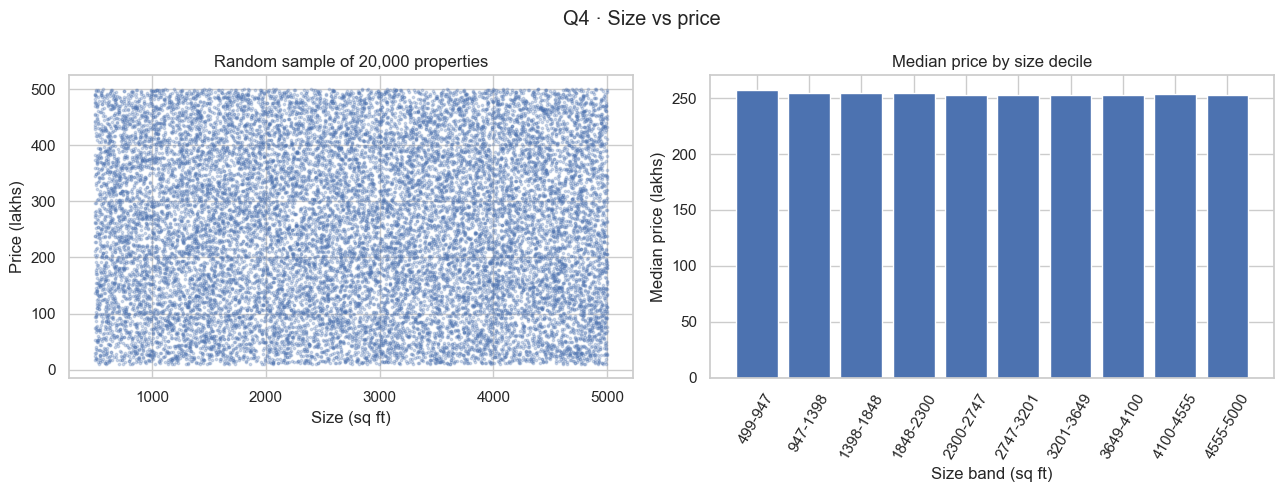

In [51]:
r_p, p_p = stats.pearsonr(eda["Size_in_SqFt"], eda["Price_in_Lakhs"])
r_s, p_s = stats.spearmanr(eda["Size_in_SqFt"], eda["Price_in_Lakhs"])
print(f"Pearson r  = {r_p:.4f} (p = {p_p:.3f})")
print(f"Spearman r = {r_s:.4f} (p = {p_s:.3f})")

size_decile = pd.qcut(eda["Size_in_SqFt"], 10)
by_decile = eda.groupby(size_decile, observed=True)["Price_in_Lakhs"].agg(["median", "mean"])
by_decile.index = [f"{int(i.left)}-{int(i.right)}" for i in by_decile.index]
display(by_decile.round(1))

sample = eda.sample(20_000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(sample["Size_in_SqFt"], sample["Price_in_Lakhs"], s=3, alpha=0.25)
axes[0].set_xlabel("Size (sq ft)"); axes[0].set_ylabel("Price (lakhs)"); axes[0].set_title("Random sample of 20,000 properties")
axes[1].bar(by_decile.index, by_decile["median"], color="#4C72B0")
axes[1].set_xlabel("Size band (sq ft)"); axes[1].set_ylabel("Median price (lakhs)"); axes[1].set_title("Median price by size decile")
axes[1].tick_params(axis="x", rotation=60)
fig.suptitle("Q4 · Size vs price")
save_fig("q04_size_vs_price")

**Interpretation (based on the output above):** 
The correlation between size and price is **−0.0025** (Pearson and Spearman, p = 0.206): no relationship. The median price in each size decile stays between 252.3 and 257.4 lakhs with no upward pattern, and the scatter plot is an evenly filled rectangle. In real markets bigger properties usually cost more; **in this data they do not.** A consequence is that price per sq ft falls as size rises, purely because we divide by size (Q11 shows r = −0.61).

## Q5. Are there any outliers in price per sq ft or property size?
We use the IQR rule explained in Section 4.6 and a second check, the **z-score** (how many standard deviations from the mean; |z| > 3 is a common warning level).

,IQR_outliers,pct_IQR,z_above_3,min,max
column,,,,,
Size_in_SqFt,0,0,0,500.0000,"5,000.0"
Price_in_Lakhs,0,0,0,10.0000,500.0000
Price_per_SqFt_INR,19723,7.8900,6231,202.2500,"99,182.0"



Price-per-sqft upper fence: ₹32,764. Flagged properties: 19,723
Median size of flagged properties: 799.0 sq ft  | median size of all: 2747.0
Flagged properties smaller than 1,000 sq ft: 74.0%

Ten highest price-per-sqft records:


,ID,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt_INR
26780,26781,500,495.9100,"99,182.0"
152905,152906,504,499.4000,"99,087.3"
59050,59051,503,498.1200,"99,029.8"
90192,90193,507,499.3200,"98,485.2"
162739,162740,505,497.0700,"98,429.7"
121347,121348,501,493.0900,"98,421.2"
147871,147872,506,494.7000,"97,766.8"
53970,53971,503,491.2500,"97,664.0"
148754,148755,502,490.0600,"97,621.5"
92665,92666,501,489.0600,"97,616.8"


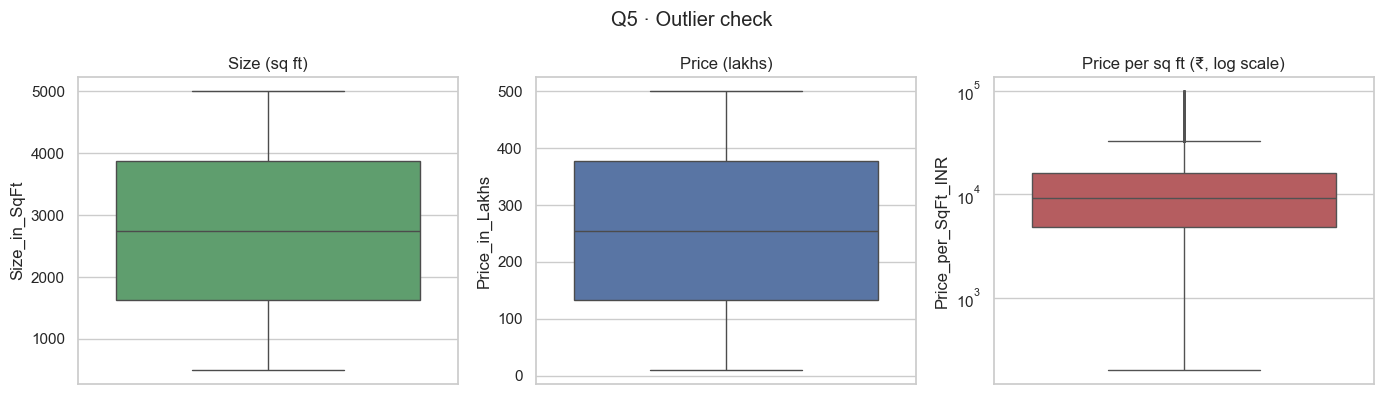

In [52]:
def count_iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

rows = []
for name in ["Size_in_SqFt", "Price_in_Lakhs", PPSF]:
    s = eda[name]
    z = (s - s.mean()) / s.std()
    rows.append({"column": name, "IQR_outliers": count_iqr_outliers(s), "pct_IQR": round(100 * count_iqr_outliers(s) / len(s), 2),
                 "z_above_3": int((z.abs() > 3).sum()), "min": s.min(), "max": s.max()})
display(pd.DataFrame(rows).set_index("column").round(2))

q1, q3 = eda[PPSF].quantile([0.25, 0.75]); fence = q3 + 1.5 * (q3 - q1)
flagged = eda[eda[PPSF] > fence]
print(f"\nPrice-per-sqft upper fence: ₹{fence:,.0f}. Flagged properties: {len(flagged):,}")
print("Median size of flagged properties:", flagged["Size_in_SqFt"].median(), "sq ft  | median size of all:", eda["Size_in_SqFt"].median())
print(f"Flagged properties smaller than 1,000 sq ft: {(flagged['Size_in_SqFt'] < 1000).mean() * 100:.1f}%")
print("\nTen highest price-per-sqft records:")
display(eda.nlargest(10, PPSF)[["ID", "Size_in_SqFt", "Price_in_Lakhs", PPSF]])

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(y=eda["Size_in_SqFt"], ax=axes[0], color="#55A868"); axes[0].set_title("Size (sq ft)")
sns.boxplot(y=eda["Price_in_Lakhs"], ax=axes[1], color="#4C72B0"); axes[1].set_title("Price (lakhs)")
sns.boxplot(y=eda[PPSF], ax=axes[2], color="#C44E52", fliersize=1); axes[2].set_yscale("log"); axes[2].set_title("Price per sq ft (₹, log scale)")
fig.suptitle("Q5 · Outlier check")
save_fig("q05_outliers")

**Interpretation (based on the output above):** 
- `Size_in_SqFt` and `Price_in_Lakhs`: **0 outliers** by the IQR rule and 0 by the z-score rule.
- Price per sq ft: **19,723 IQR outliers (7.89%)** and 6,231 with |z| > 3, all on the high side, up to ₹99,182 per sq ft (minimum ₹202).
- The flagged properties have a median size of 799 sq ft, 74.0% are under 1,000 sq ft, and the ten highest records are all 500–507 sq ft properties priced at about 489–499 lakhs.
- **Conclusion:** the only outliers are in price per sq ft, and they come from small sizes combined with high prices. They are not recording errors, so they are kept (Section 5.6).

---
# Questions 6–10: Location-based Analysis

## Q6. What is the average price per sq ft by state?

,count,mean,median,std,ci95_half_width
State,,,,,
Karnataka,12424,"13,252.0","9,384.0","13,221.0",232.0000
Andhra Pradesh,12462,"13,202.0","9,287.0","13,248.0",233.0000
Uttar Pradesh,12508,"13,143.0","9,441.0","12,979.0",227.0000
Tamil Nadu,12629,"13,132.0","9,301.0","13,210.0",230.0000
Telangana,12539,"13,093.0","9,291.0","13,045.0",228.0000
Gujarat,12578,"13,091.0","9,331.0","13,092.0",229.0000
Assam,12496,"13,084.0","9,255.0","13,117.0",230.0000
Maharashtra,12533,"13,070.0","9,361.0","12,977.0",227.0000
Madhya Pradesh,12451,"13,069.0","9,236.0","12,988.0",228.0000


Highest state mean minus lowest state mean = 2.5% of the overall mean (₹13,058)
ANOVA p-value (are the state means different?): 0.9564
Eta squared: 0.000039


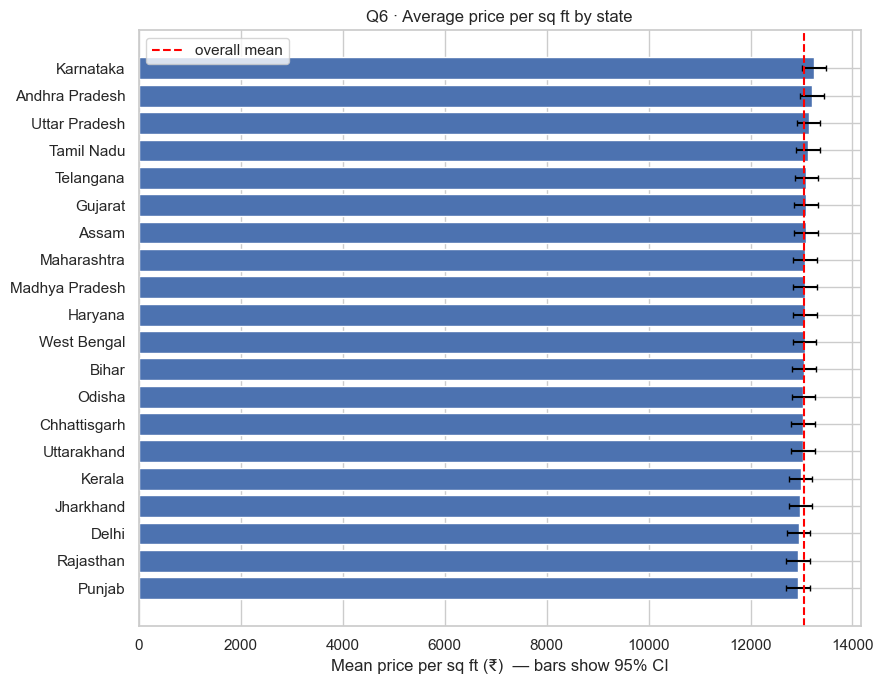

In [53]:
t6 = group_table(eda, "State", PPSF).sort_values("mean", ascending=False)
display(t6.round(0))
spread = (t6["mean"].max() - t6["mean"].min()) / eda[PPSF].mean() * 100
print(f"Highest state mean minus lowest state mean = {spread:.1f}% of the overall mean (₹{eda[PPSF].mean():,.0f})")
print("ANOVA p-value (are the state means different?):", f"{stats.f_oneway(*[g.values for _, g in eda.groupby('State')[PPSF]]).pvalue:.4f}")
print("Eta squared:", f"{eta_squared(eda, 'State', PPSF):.6f}")

fig, ax = plt.subplots(figsize=(9, 7))
order = t6.sort_values("mean")
ax.barh(order.index, order["mean"], xerr=order["ci95_half_width"], color="#4C72B0", ecolor="black", capsize=2)
ax.axvline(eda[PPSF].mean(), color="red", linestyle="--", label="overall mean"); ax.legend()
ax.set_xlabel("Mean price per sq ft (₹)  — bars show 95% CI"); ax.set_title("Q6 · Average price per sq ft by state")
save_fig("q06_ppsf_by_state")

**Interpretation (based on the output above):** 
State averages range from ₹12,931 (Punjab) to ₹13,252 (Karnataka); the gap is **2.5% of the overall mean** (₹13,058), while each state's 95% interval is about ±₹230, so the intervals overlap. The ANOVA p-value is 0.956 and the state explains 0.004% of the variation (η² = 0.000039). The ranking in the chart is therefore **not meaningful**: with no real differences, someone has to come first. Medians are similar too (₹9,142 to ₹9,441).

## Q7. What is the average property price by city?

Five highest and five lowest cities by mean price (lakhs):


,count,mean,median,std,ci95_half_width
City,,,,,
Bangalore,4144,258.5000,258.4000,141.3000,4.3000
Surat,6167,258.1000,258.2000,142.0000,3.5000
Kochi,6305,257.4000,258.8000,141.5000,3.5000
Gaya,6170,257.1000,257.2000,141.9000,3.5000
Mangalore,4063,256.9000,256.5000,142.9000,4.4000
Mumbai,4149,252.1000,249.0000,140.4000,4.3000
Bilaspur,6263,251.9000,251.4000,141.5000,3.5000
New Delhi,6306,251.6000,249.7000,140.8000,3.5000
Trivandrum,6182,251.3000,249.1000,140.0000,3.5000


Highest city mean minus lowest city mean = 3.0% of the overall mean (254.6 lakhs)
ANOVA p-value: 0.2232
Eta squared: 0.000190 (about 0.000164 would be expected from pure chance with 42 groups)


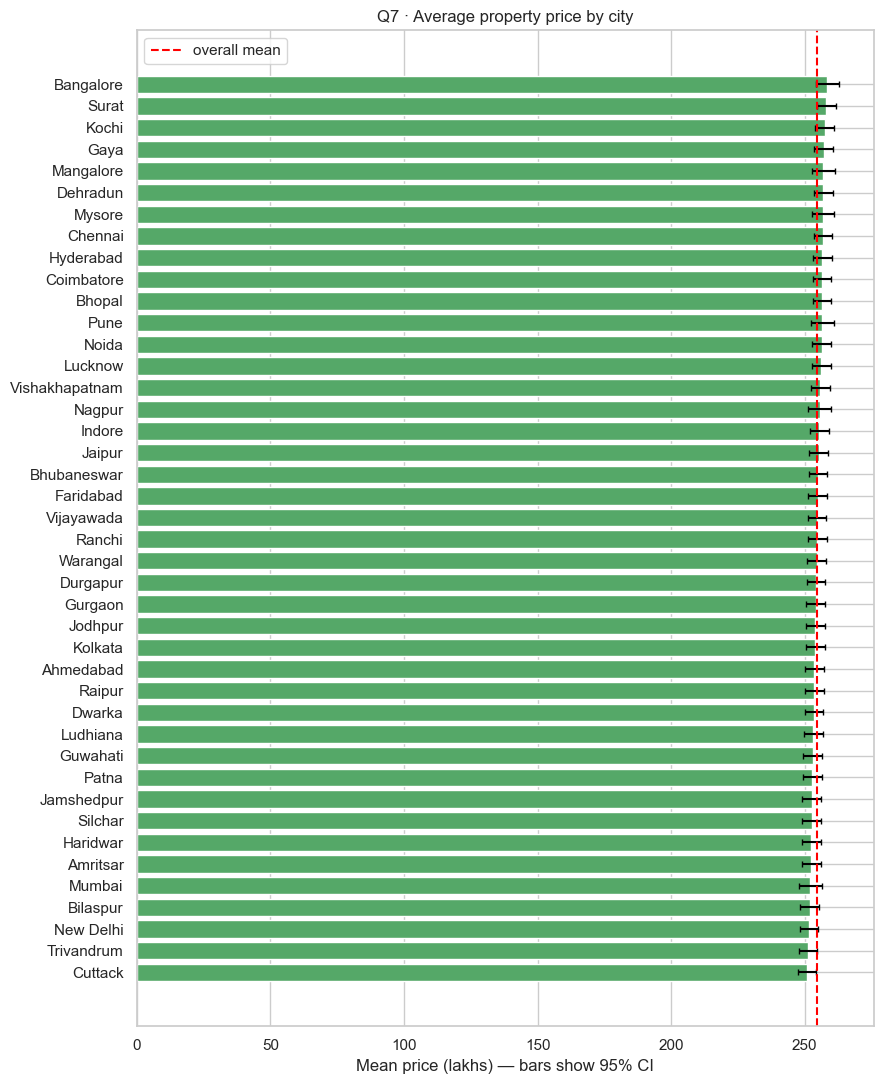

In [54]:
t7 = group_table(eda, "City", "Price_in_Lakhs").sort_values("mean", ascending=False)
print("Five highest and five lowest cities by mean price (lakhs):")
display(pd.concat([t7.head(5), t7.tail(5)]).round(1))
spread = (t7["mean"].max() - t7["mean"].min()) / eda["Price_in_Lakhs"].mean() * 100
print(f"Highest city mean minus lowest city mean = {spread:.1f}% of the overall mean ({eda['Price_in_Lakhs'].mean():.1f} lakhs)")
print("ANOVA p-value:", f"{stats.f_oneway(*[g.values for _, g in eda.groupby('City')['Price_in_Lakhs']]).pvalue:.4f}")
print("Eta squared:", f"{eta_squared(eda, 'City', 'Price_in_Lakhs'):.6f}",
      f"(about {(eda['City'].nunique() - 1) / (len(eda) - 1):.6f} would be expected from pure chance with 42 groups)")

fig, ax = plt.subplots(figsize=(9, 11))
order = t7.sort_values("mean")
ax.barh(order.index, order["mean"], xerr=order["ci95_half_width"], color="#55A868", ecolor="black", capsize=2)
ax.axvline(eda["Price_in_Lakhs"].mean(), color="red", linestyle="--", label="overall mean"); ax.legend()
ax.set_xlabel("Mean price (lakhs) — bars show 95% CI"); ax.set_title("Q7 · Average property price by city")
save_fig("q07_price_by_city")

**Interpretation (based on the output above):** 
City mean prices range from 250.8 lakhs (Cuttack) to 258.5 lakhs (Bangalore), a gap of **3.0% of the overall mean** (254.6). Each city's interval is about ±3.5 to ±4.4 lakhs, the ANOVA p-value is 0.223, and η² = 0.000190 against 0.000164 expected from pure chance. So **no city is clearly more expensive than another**. Mumbai (252.1) and New Delhi (251.6) sit among the five lowest, whereas real markets normally show large city differences; such patterns are absent here.

## Q8. What is the median age of properties by locality?
There are 500 localities. We compute each locality's median age and look at how spread out these 500 numbers are. As a yardstick, we also estimate how much a median would wobble **by pure chance** with this many properties per locality (the standard error of a median ≈ 1.2533 × std ÷ √n).

Distribution of the 500 locality median ages:
count   500.0000
mean     18.4800
std       0.7800
min      16.0000
25%      18.0000
50%      18.0000
75%      19.0000
max      21.0000

Oldest 10 localities (by median age):


,count,median
Locality,,
Locality_72,495,21.0000
Locality_403,471,21.0000
Locality_224,548,20.0000
Locality_396,543,20.0000
Locality_234,538,20.0000
Locality_270,530,20.0000
Locality_499,528,20.0000
Locality_334,526,20.0000
Locality_366,526,20.0000


Youngest 10 localities (by median age):


,count,median
Locality,,
Locality_443,520,16.0000
Locality_92,458,17.0000
Locality_222,460,17.0000
Locality_56,461,17.0000
Locality_278,468,17.0000
Locality_325,468,17.0000
Locality_179,469,17.0000
Locality_54,471,17.0000
Locality_71,471,17.0000



Overall median age: 18.0. Chance-only 95% range for a locality median: 16.9 to 19.1
Localities whose median falls inside that range: 91.0%


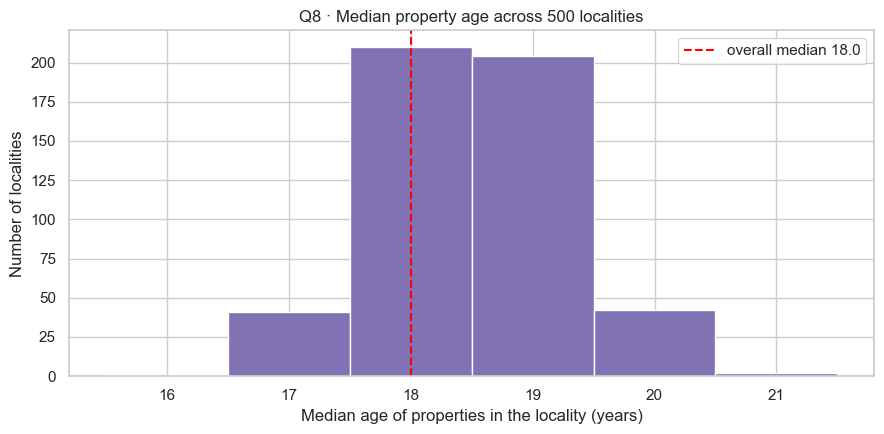

In [55]:
loc_age = eda.groupby("Locality")["Age_of_Property"].agg(["count", "median"])
print("Distribution of the 500 locality median ages:")
print(loc_age["median"].describe().round(2).to_string())
print("\nOldest 10 localities (by median age):");  display(loc_age.sort_values(["median", "count"], ascending=False).head(10))
print("Youngest 10 localities (by median age):"); display(loc_age.sort_values(["median", "count"]).head(10))

overall_median = eda["Age_of_Property"].median()
se_median = 1.2533 * eda["Age_of_Property"].std() / np.sqrt(loc_age["count"].median())
lo, hi = overall_median - 1.96 * se_median, overall_median + 1.96 * se_median
inside = loc_age["median"].between(lo, hi).mean() * 100
print(f"\nOverall median age: {overall_median}. Chance-only 95% range for a locality median: {lo:.1f} to {hi:.1f}")
print(f"Localities whose median falls inside that range: {inside:.1f}%")

plt.figure(figsize=(9, 4.5))
plt.hist(loc_age["median"], bins=np.arange(loc_age["median"].min() - 0.5, loc_age["median"].max() + 1.5, 1), color="#8172B3", edgecolor="white")
plt.axvline(overall_median, color="red", linestyle="--", label=f"overall median {overall_median}")
plt.xlabel("Median age of properties in the locality (years)"); plt.ylabel("Number of localities")
plt.title("Q8 · Median property age across 500 localities"); plt.legend()
save_fig("q08_median_age_by_locality")

**Interpretation (based on the output above):** 
The 500 locality median ages range from 16 to 21 years (mean 18.48, spread 0.78 years) around an overall median of 18. By pure chance alone we would expect a locality median to fall between about 16.9 and 19.1, and **91.0%** of localities do. The slightly larger share outside than the nominal 5% is not surprising: the rough formula assumes a bell-shaped distribution, whereas ages here are evenly spread, for which medians wobble more. The "oldest" (Locality_72, Locality_403 at 21) and "youngest" (Locality_443 at 16) localities are therefore just random extremes. Remember also that each locality label mixes properties from all cities.

## Q9. How is BHK distributed across cities?

Overall BHK share (%):
BHK
1   20.0800
2   19.9300
3   20.0300
4   19.9200
5   20.0500

For each BHK, the city with the highest and lowest share (%):


,highest_city,highest_%,lowest_city,lowest_%
BHK,,,,
1,Gaya,21.9800,Hyderabad,18.9700
2,Hyderabad,20.9200,New Delhi,18.7800
3,Trivandrum,21.0100,Gaya,18.5700
4,Vishakhapatnam,21.4900,Noida,19.0200
5,Ahmedabad,21.0600,Cuttack,19.0200


Chi-square test of independence (does BHK mix depend on city?): chi2 = 186.5, dof = 164, p = 0.1098


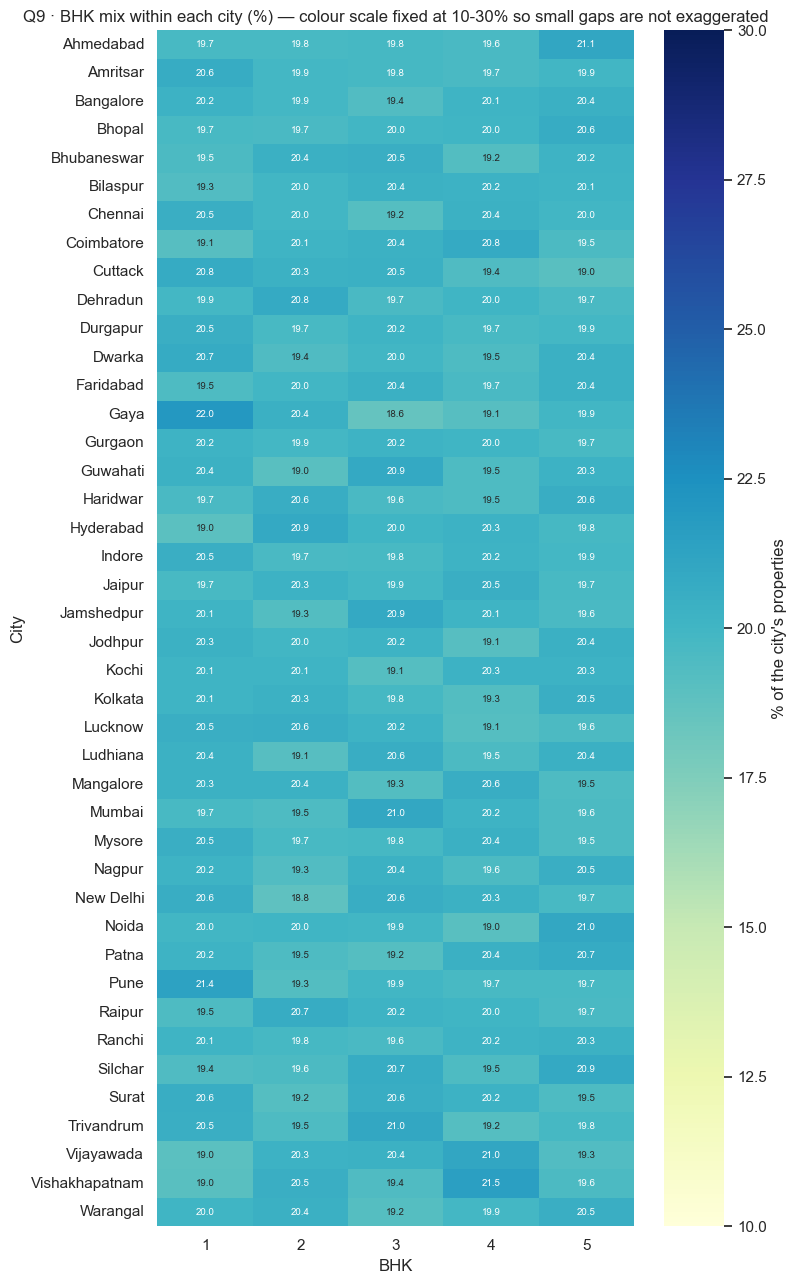

In [56]:
ct_pct = pd.crosstab(eda["City"], eda["BHK"], normalize="index") * 100
print("Overall BHK share (%):"); print((eda["BHK"].value_counts(normalize=True).sort_index() * 100).round(2).to_string())
print("\nFor each BHK, the city with the highest and lowest share (%):")
summary9 = pd.DataFrame({"highest_city": ct_pct.idxmax(), "highest_%": ct_pct.max(), "lowest_city": ct_pct.idxmin(), "lowest_%": ct_pct.min()})
display(summary9.round(2))
chi2, p_chi, dof, _ = stats.chi2_contingency(pd.crosstab(eda["City"], eda["BHK"]))
print(f"Chi-square test of independence (does BHK mix depend on city?): chi2 = {chi2:.1f}, dof = {dof}, p = {p_chi:.4f}")

plt.figure(figsize=(8, 13))
sns.heatmap(ct_pct, annot=True, fmt=".1f", cmap="YlGnBu", vmin=10, vmax=30, cbar_kws={"label": "% of the city's properties"}, annot_kws={"size": 7})
plt.title("Q9 · BHK mix within each city (%) — colour scale fixed at 10-30% so small gaps are not exaggerated")
save_fig("q09_bhk_by_city")

**Interpretation (based on the output above):** 
Across the whole dataset each BHK value holds about 20% of properties (19.92% to 20.08%). City by city, a BHK share ranges only from 18.57% to 21.98%, and the chi-square test (χ² = 186.5, 164 degrees of freedom, p = 0.110) finds **no evidence that the BHK mix depends on the city**. The heatmap's colour scale is deliberately fixed at 10–30%, so that the small gaps are not exaggerated; almost every cell is close to 20%.

## Q10. What are the price trends for the top 5 most expensive localities?
**Important limitation:** the dataset has *no date of sale or listing*, so a true price-over-time trend **cannot** be drawn. The only time-like column is `Year_Built` (when the building was made). We therefore:
1. define "most expensive" as the **highest median price** (aggregated over all cities, because locality names repeat across cities),
2. show median price by **construction-year band** as a *proxy* — this compares different buildings, it does **not** show how a property's price changed,
3. check whether the "top 5" is stable or just noise.

Top 5 localities by median price (lakhs):
Locality
Locality_395   282.6800
Locality_366   282.3300
Locality_303   282.2700
Locality_79    280.7600
Locality_203   280.3200
Median across all 500 localities: 253.51 | overall median: 253.87

Median price (lakhs) by construction-year band:


Locality,Locality_203,Locality_303,Locality_366,Locality_395,Locality_79
Year_Built,,,,,
1990-94,295.4000,280.7000,311.7000,234.2000,248.5000
1995-99,254.2000,253.3000,273.0000,314.4000,300.0000
2000-04,294.2000,288.2000,264.3000,312.0000,307.0000
2005-09,246.3000,290.9000,292.3000,237.3000,254.5000
2010-14,274.4000,275.7000,289.3000,329.6000,309.8000
2015-19,269.4000,276.6000,287.0000,286.6000,245.8000
2020-23,328.9000,302.2000,309.1000,251.3000,277.9000


Properties behind each point (min / max): 53 / 92


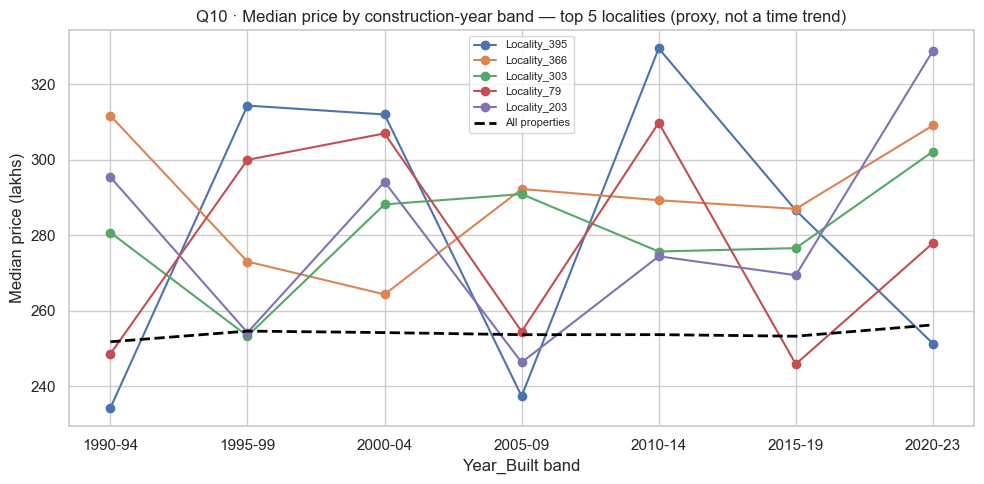


Top 5 in random half A: ['Locality_203', 'Locality_360', 'Locality_439', 'Locality_78', 'Locality_89']
Top 5 in random half B: ['Locality_284', 'Locality_285', 'Locality_381', 'Locality_395', 'Locality_487']
Localities in BOTH halves' top 5: 0 | overlap with the full-data top 5 (A / B): 1 / 1
Spearman correlation between Year_Built and Price (whole dataset): 0.0027


In [57]:
loc_median_price = eda.groupby("Locality")["Price_in_Lakhs"].median()
top5 = loc_median_price.nlargest(5).index.tolist()
print("Top 5 localities by median price (lakhs):"); print(loc_median_price.nlargest(5).round(2).to_string())
print("Median across all 500 localities:", round(loc_median_price.median(), 2), "| overall median:", round(eda["Price_in_Lakhs"].median(), 2))

bins = [1989, 1994, 1999, 2004, 2009, 2014, 2019, 2023]
labels = ["1990-94", "1995-99", "2000-04", "2005-09", "2010-14", "2015-19", "2020-23"]
band = pd.cut(eda["Year_Built"], bins=bins, labels=labels)
sub = eda[eda["Locality"].isin(top5)]
trend = sub.groupby([band[sub.index], "Locality"], observed=True)["Price_in_Lakhs"].agg(["median", "count"])
trend_median = trend["median"].unstack()
overall_band = eda.groupby(band, observed=True)["Price_in_Lakhs"].median()
print("\nMedian price (lakhs) by construction-year band:"); display(trend_median.round(1))
print("Properties behind each point (min / max):", int(trend["count"].min()), "/", int(trend["count"].max()))

fig, ax = plt.subplots(figsize=(10, 5))
for loc in top5:
    ax.plot(trend_median.index.astype(str), trend_median[loc], marker="o", label=loc)
ax.plot(overall_band.index.astype(str), overall_band.values, color="black", linestyle="--", linewidth=2, label="All properties")
ax.set_xlabel("Year_Built band"); ax.set_ylabel("Median price (lakhs)")
ax.set_title("Q10 · Median price by construction-year band — top 5 localities (proxy, not a time trend)"); ax.legend(fontsize=8)
save_fig("q10_top5_locality_trend")

# Is the top 5 stable? Split the rows randomly into two halves and compare.
rng = np.random.RandomState(SEED)
half = rng.rand(len(eda)) < 0.5
top_a = set(eda[half].groupby("Locality")["Price_in_Lakhs"].median().nlargest(5).index)
top_b = set(eda[~half].groupby("Locality")["Price_in_Lakhs"].median().nlargest(5).index)
print("\nTop 5 in random half A:", sorted(top_a)); print("Top 5 in random half B:", sorted(top_b))
print("Localities in BOTH halves' top 5:", len(top_a & top_b), "| overlap with the full-data top 5 (A / B):", len(top_a & set(top5)), "/", len(top_b & set(top5)))
print("Spearman correlation between Year_Built and Price (whole dataset):", round(stats.spearmanr(eda["Year_Built"], eda["Price_in_Lakhs"])[0], 4))

**Interpretation (based on the output above):** 
- The five localities with the highest median price are Locality_395 (282.68 lakhs), Locality_366 (282.33), Locality_303 (282.27), Locality_79 (280.76) and Locality_203 (280.32), about 27–29 lakhs above the typical locality median (253.51).
- But this "top 5" is **not stable**: when the rows are split randomly into two halves, the two halves' top 5 lists **share no locality at all**, and each shares only one locality with the full-data top 5. Picking the highest 5 of 500 groups will always produce above-average values by chance.
- The proxy "trend" by construction-year band **zigzags with no direction** (for example Locality_395: 234.2, 314.4, 312.0, 237.3, 329.6, 286.6, 251.3 lakhs across the seven bands, each point built from only 53–92 properties). The rank correlation between `Year_Built` and price over all rows is 0.0027.
- **Answer:** no real price trend can be shown. The dataset has no sale dates, and the construction-year proxy shows nothing beyond noise.

---
# Questions 11–15: Feature Relationships & Correlation

## Q11. How are numeric features correlated with each other?
Three pairs are linked **by definition** (so a strong correlation there is expected and tells us nothing new): `Year_Built`↔`Age_of_Property`, and `Price_per_SqFt_exact` with both `Size_in_SqFt` and `Price_in_Lakhs`. We separate those from the rest.

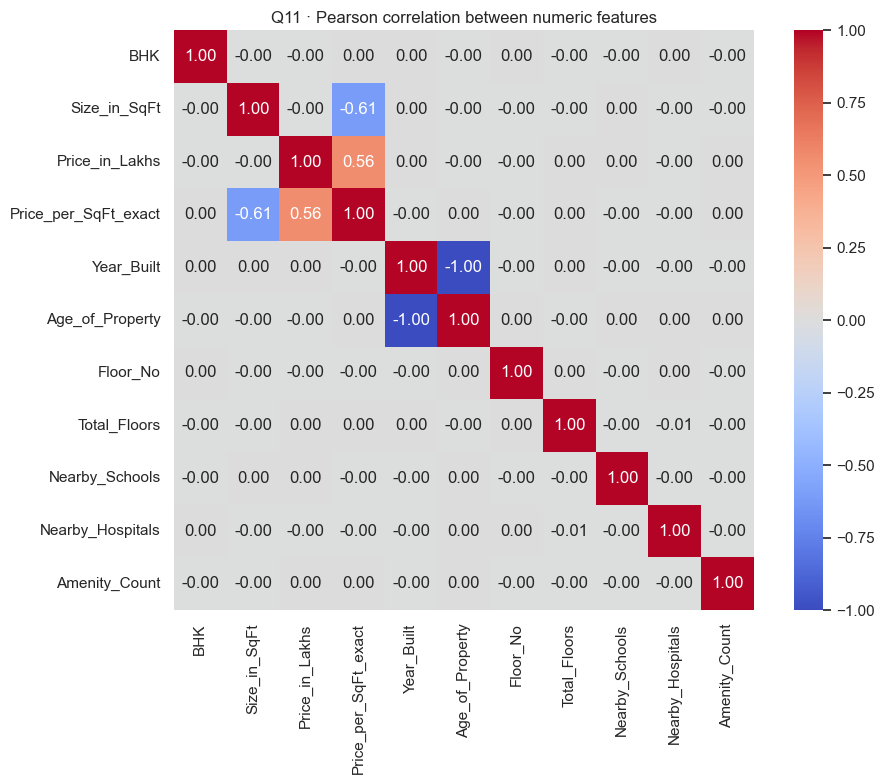

Strongest pairs:


,feature_1,feature_2,pearson_r,abs_r,linked_by_definition
34,Year_Built,Age_of_Property,-1.0000,1.0000,True
11,Size_in_SqFt,Price_per_SqFt_exact,-0.6146,0.6146,True
19,Price_in_Lakhs,Price_per_SqFt_exact,0.5558,0.5558,True
50,Total_Floors,Nearby_Hospitals,-0.005900,0.005900,False
30,Price_per_SqFt_exact,Total_Floors,0.004200,0.004200,False
12,Size_in_SqFt,Year_Built,0.004100,0.004100,False
13,Size_in_SqFt,Age_of_Property,-0.004100,0.004100,False
36,Year_Built,Total_Floors,0.003500,0.003500,False


Largest |r| among the 52 pairs NOT linked by definition: 0.0059
           feature_1        feature_2  pearson_r
        Total_Floors Nearby_Hospitals  -0.005900
Price_per_SqFt_exact     Total_Floors   0.004200
        Size_in_SqFt       Year_Built   0.004100

Spearman (rank) correlation: largest |rho| outside the three defined pairs = 0.0059


In [58]:
corr_cols = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt_exact", "Year_Built", "Age_of_Property",
             "Floor_No", "Total_Floors", "Nearby_Schools", "Nearby_Hospitals", "Amenity_Count"]
corr = eda[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Q11 · Pearson correlation between numeric features")
save_fig("q11_correlation_heatmap")

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("pearson_r").reset_index()
pairs.columns = ["feature_1", "feature_2", "pearson_r"]
pairs["abs_r"] = pairs["pearson_r"].abs()
mechanical = [{"Year_Built", "Age_of_Property"}, {"Price_per_SqFt_exact", "Size_in_SqFt"}, {"Price_per_SqFt_exact", "Price_in_Lakhs"}]
pairs["linked_by_definition"] = pairs.apply(lambda r: {r["feature_1"], r["feature_2"]} in mechanical, axis=1)
print("Strongest pairs:")
display(pairs.sort_values("abs_r", ascending=False).head(8).round(4))
others = pairs[~pairs["linked_by_definition"]]
print(f"Largest |r| among the {len(others)} pairs NOT linked by definition: {others['abs_r'].max():.4f}")
print(others.sort_values("abs_r", ascending=False).head(3)[["feature_1", "feature_2", "pearson_r"]].round(4).to_string(index=False))

sp = eda[corr_cols].corr(method="spearman")
sp_pairs = sp.where(np.triu(np.ones(sp.shape), k=1).astype(bool)).stack()
print(f"\nSpearman (rank) correlation: largest |rho| outside the three defined pairs = "
      f"{sp_pairs[[i for i in sp_pairs.index if {i[0], i[1]} not in mechanical]].abs().max():.4f}")

**Interpretation (based on the output above):** 
Only three pairs are strongly correlated, and all are linked by definition: `Year_Built` and `Age_of_Property` (−1.00), `Size_in_SqFt` and `Price_per_SqFt_exact` (−0.61), and `Price_in_Lakhs` and `Price_per_SqFt_exact` (0.56). Among the other 115 pairs, the largest absolute correlation is **0.0059** (Total_Floors vs Nearby_Hospitals); the Spearman rank version gives the same maximum. So the numeric features are **practically independent of one another**, and the only strong links come from formulas — which is also why price per sq ft must not be fed to a model together with price and size.

## Q12. How do nearby schools relate to price per sq ft?
`Nearby_Schools` takes values 1–10. We compare the average price per sq ft at each level.

,count,mean,median,std,ci95_half_width
Nearby_Schools,,,,,
1,25360,"13,061.0","9,261.0","13,002.0",160.0000
2,24851,"13,123.0","9,291.0","13,062.0",162.0000
3,25045,"13,073.0","9,273.0","13,023.0",161.0000
4,24739,"12,888.0","9,259.0","12,790.0",159.0000
5,25023,"12,993.0","9,188.0","13,013.0",161.0000
6,24824,"13,292.0","9,352.0","13,469.0",168.0000
7,24808,"13,041.0","9,233.0","13,037.0",162.0000
8,25290,"12,953.0","9,144.0","13,088.0",161.0000
9,24823,"13,103.0","9,265.0","13,070.0",163.0000


Pearson r = -0.0001 (p = 0.977) | Spearman rho = -0.0023 (p = 0.256)
Highest level mean minus lowest level mean = 3.1% of overall mean


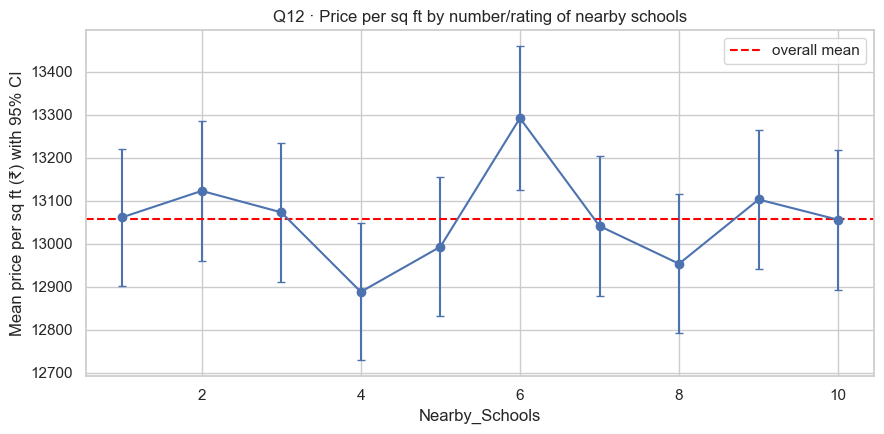

In [59]:
def relationship_by_level(col, title, filename, color):
    t = group_table(eda, col, PPSF)
    display(t.round(0))
    r_p, p_p = stats.pearsonr(eda[col], eda[PPSF]); r_s, p_s = stats.spearmanr(eda[col], eda[PPSF])
    print(f"Pearson r = {r_p:.4f} (p = {p_p:.3f}) | Spearman rho = {r_s:.4f} (p = {p_s:.3f})")
    print(f"Highest level mean minus lowest level mean = {(t['mean'].max() - t['mean'].min()) / eda[PPSF].mean() * 100:.1f}% of overall mean")
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.errorbar(t.index, t["mean"], yerr=t["ci95_half_width"], marker="o", color=color, capsize=3)
    ax.axhline(eda[PPSF].mean(), color="red", linestyle="--", label="overall mean")
    ax.set_xlabel(col); ax.set_ylabel("Mean price per sq ft (₹) with 95% CI"); ax.set_title(title); ax.legend()
    save_fig(filename)

relationship_by_level("Nearby_Schools", "Q12 · Price per sq ft by number/rating of nearby schools", "q12_ppsf_by_schools", "#4C72B0")

**Interpretation (based on the output above):** 
Mean price per sq ft by school level ranges from ₹12,888 (level 4) to ₹13,292 (level 6), a spread of 3.1% of the overall mean, with intervals of about ±₹160 that overlap, and no steady rise or fall across levels 1 to 10. The correlation is −0.0001 (Pearson, p = 0.977) and −0.0023 (Spearman, p = 0.256). **No relationship** between nearby schools and price per sq ft is visible.

## Q13. How do nearby hospitals relate to price per sq ft?

,count,mean,median,std,ci95_half_width
Nearby_Hospitals,,,,,
1,25075,"13,020.0","9,256.0","12,990.0",161.0000
2,24960,"13,025.0","9,309.0","12,979.0",161.0000
3,24834,"13,234.0","9,349.0","13,254.0",165.0000
4,25168,"12,996.0","9,271.0","12,984.0",160.0000
5,25102,"12,917.0","9,149.0","12,949.0",160.0000
6,25082,"13,007.0","9,129.0","13,069.0",162.0000
7,24887,"13,257.0","9,334.0","13,251.0",165.0000
8,24891,"13,116.0","9,224.0","13,203.0",164.0000
9,25014,"13,084.0","9,283.0","13,035.0",162.0000


Pearson r = -0.0001 (p = 0.951) | Spearman rho = -0.0017 (p = 0.388)
Highest level mean minus lowest level mean = 2.6% of overall mean


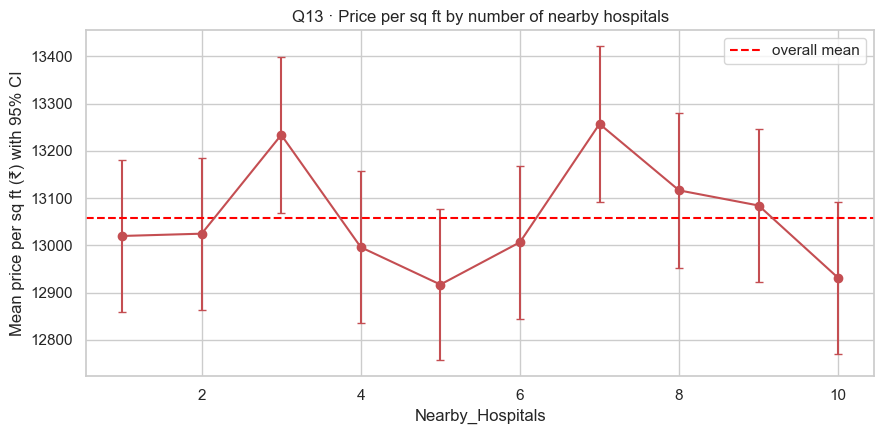

In [60]:
relationship_by_level("Nearby_Hospitals", "Q13 · Price per sq ft by number of nearby hospitals", "q13_ppsf_by_hospitals", "#C44E52")

**Interpretation (based on the output above):** 
Mean price per sq ft by hospital level ranges from ₹12,917 (level 5) to ₹13,257 (level 7), a spread of 2.6% of the overall mean, with overlapping intervals of about ±₹160 and no trend. The correlation is −0.0001 (Pearson, p = 0.951) and −0.0017 (Spearman, p = 0.388). **No relationship** with nearby hospitals is visible.

## Q14. How does price vary by furnished status?

,count,mean,median,std,ci95_half_width
Furnished_Status,,,,,
Furnished,83218,254.4500,253.5600,141.2000,0.9600
Semi-furnished,83374,254.3300,253.8100,141.4500,0.9600
Unfurnished,83408,254.9800,254.1900,141.4000,0.9600


Kruskal-Wallis p-value: 0.6089
Eta squared: 0.000004
Highest group mean minus lowest = 0.64 lakhs (0.25% of the overall mean)


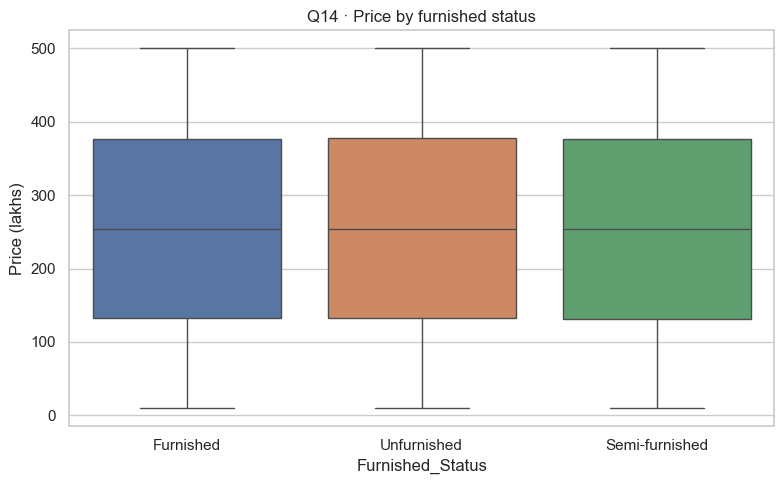

In [61]:
t14 = group_table(eda, "Furnished_Status", "Price_in_Lakhs")
display(t14.round(2))
print("Kruskal-Wallis p-value:", f"{kruskal_p(eda, 'Furnished_Status', 'Price_in_Lakhs'):.4f}")
print("Eta squared:", f"{eta_squared(eda, 'Furnished_Status', 'Price_in_Lakhs'):.6f}")
print(f"Highest group mean minus lowest = {(t14['mean'].max() - t14['mean'].min()):.2f} lakhs ({(t14['mean'].max() - t14['mean'].min()) / eda['Price_in_Lakhs'].mean() * 100:.2f}% of the overall mean)")

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=eda, x="Furnished_Status", y="Price_in_Lakhs", hue="Furnished_Status", legend=False, ax=ax)
ax.set_title("Q14 · Price by furnished status"); ax.set_ylabel("Price (lakhs)")
save_fig("q14_price_by_furnished")

**Interpretation (based on the output above):** 
Mean prices are 254.45 lakhs (Furnished), 254.33 (Semi-furnished) and 254.98 (Unfurnished). The largest gap is 0.64 lakhs, or **0.25% of the overall mean**, smaller than the ±0.96 interval of each group. The Kruskal-Wallis p-value is 0.609 and η² = 0.000004. **Furnishing level does not change price in this data**; unfurnished properties are even marginally higher, which is the opposite of what one would expect in reality but is within noise.

## Q15. How does price per sq ft vary by property facing direction?

,count,mean,median,std,ci95_half_width
Facing,,,,,
East,62269,"13,024.0","9,234.0","13,015.0",102.0000
North,62637,"13,025.0","9,219.0","13,034.0",102.0000
South,62337,"13,044.0","9,225.0","13,109.0",103.0000
West,62757,"13,140.0","9,308.0","13,129.0",103.0000


Kruskal-Wallis p-value: 0.3461
Eta squared: 0.000013
Highest group mean minus lowest = 0.89% of overall mean


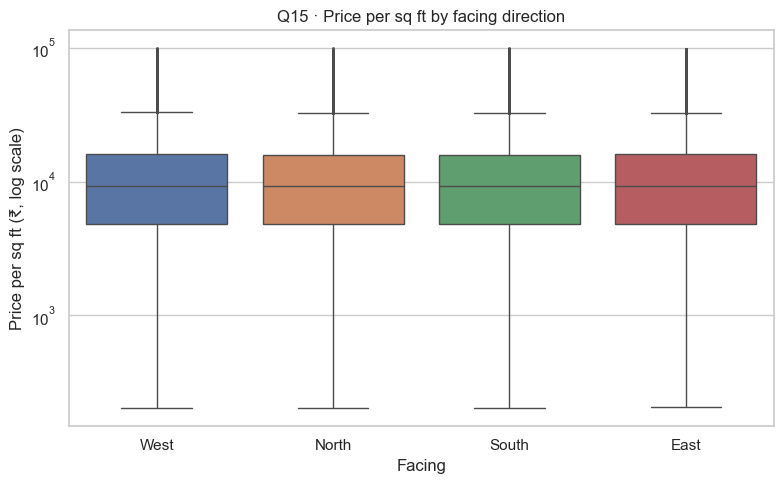

In [62]:
t15 = group_table(eda, "Facing", PPSF)
display(t15.round(0))
print("Kruskal-Wallis p-value:", f"{kruskal_p(eda, 'Facing', PPSF):.4f}")
print("Eta squared:", f"{eta_squared(eda, 'Facing', PPSF):.6f}")
print(f"Highest group mean minus lowest = {(t15['mean'].max() - t15['mean'].min()) / eda[PPSF].mean() * 100:.2f}% of overall mean")

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=eda, x="Facing", y=PPSF, hue="Facing", legend=False, fliersize=1, ax=ax)
ax.set_yscale("log"); ax.set_ylabel("Price per sq ft (₹, log scale)"); ax.set_title("Q15 · Price per sq ft by facing direction")
save_fig("q15_ppsf_by_facing")

**Interpretation (based on the output above):** 
Mean price per sq ft is ₹13,024 (East), ₹13,025 (North), ₹13,044 (South) and ₹13,140 (West). The gap between the highest and lowest group is **0.89% of the overall mean**, smaller than the roughly ±₹102 interval of each group. The p-value is 0.346 and η² = 0.000013. **Facing direction has no detectable effect** on price per sq ft.

---
# Questions 16–20: Investment, Amenities, Ownership & Accessibility

## Q16. How many properties belong to each owner type?

,properties,percent
Owner_Type,,
Broker,83479,33.3900
Owner,83268,33.3100
Builder,83253,33.3000


Chi-square test against 'all owner types equally common': p = 0.8256


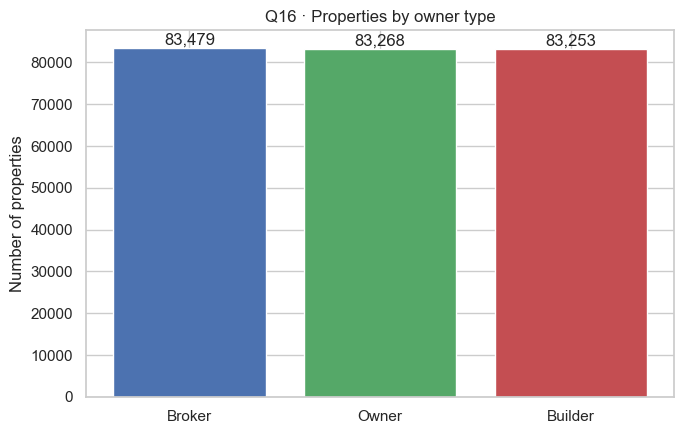

In [63]:
c16 = eda["Owner_Type"].value_counts()
t16 = pd.DataFrame({"properties": c16, "percent": (c16 / len(eda) * 100).round(2)})
display(t16)
chi = stats.chisquare(c16.values)
print(f"Chi-square test against 'all owner types equally common': p = {chi.pvalue:.4f}")

plt.figure(figsize=(7, 4.5))
bars = plt.bar(c16.index, c16.values, color=["#4C72B0", "#55A868", "#C44E52"])
for b in bars: plt.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{int(b.get_height()):,}", ha="center", va="bottom")
plt.ylabel("Number of properties"); plt.title("Q16 · Properties by owner type")
save_fig("q16_owner_type_counts")

**Interpretation (based on the output above):** 
There are 83,479 Broker (33.39%), 83,268 Owner (33.31%) and 83,253 Builder (33.30%) properties: essentially **equal thirds**, and the chi-square test against equal shares gives p = 0.826. Note the dataset's labels (Owner / Broker / Builder) differ from the PDF's (Individual / Builder / Agent).

## Q17. How many properties are available under each availability status?

,properties,percent
Availability_Status,,
Under_Construction,125035,50.0100
Ready_to_Move,124965,49.9900


Chi-square test against 'both statuses equally common': p = 0.8887
Note: the project PDF also lists 'Sold', but no row has that status: False


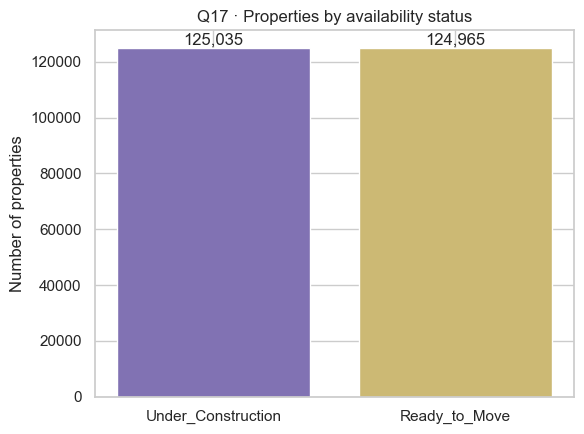

In [64]:
c17 = eda["Availability_Status"].value_counts()
t17 = pd.DataFrame({"properties": c17, "percent": (c17 / len(eda) * 100).round(2)})
display(t17)
chi = stats.chisquare(c17.values)
print(f"Chi-square test against 'both statuses equally common': p = {chi.pvalue:.4f}")
print("Note: the project PDF also lists 'Sold', but no row has that status:", "Sold" in c17.index)

plt.figure(figsize=(6, 4.5))
bars = plt.bar(c17.index, c17.values, color=["#8172B3", "#CCB974"])
for b in bars: plt.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{int(b.get_height()):,}", ha="center", va="bottom")
plt.ylabel("Number of properties"); plt.title("Q17 · Properties by availability status")
save_fig("q17_availability_counts")

**Interpretation (based on the output above):** 
There are 125,035 Under_Construction (50.01%) and 124,965 Ready_to_Move (49.99%) properties; the split is even (p = 0.889). No property has the status `Sold`, although the PDF mentions it. Remember from Section 4.4 that every "Under_Construction" property also has an old construction year.

## Q18. Does parking space affect property price?

,count,mean,median,std,ci95_half_width
Parking_Space,,,,,
No,125456,254.4300,253.3700,141.4900,0.7800
Yes,124544,254.7500,254.3600,141.2100,0.7800


Mean price difference (Yes - No): 0.32 lakhs, 95% CI [-0.79, 1.42]
That is 0.12% of the overall mean price
Welch t-test p-value: 0.5761 | Cohen's d (effect size): 0.0022  (0.2 would be called 'small')
Median difference (Yes - No): 0.99 lakhs


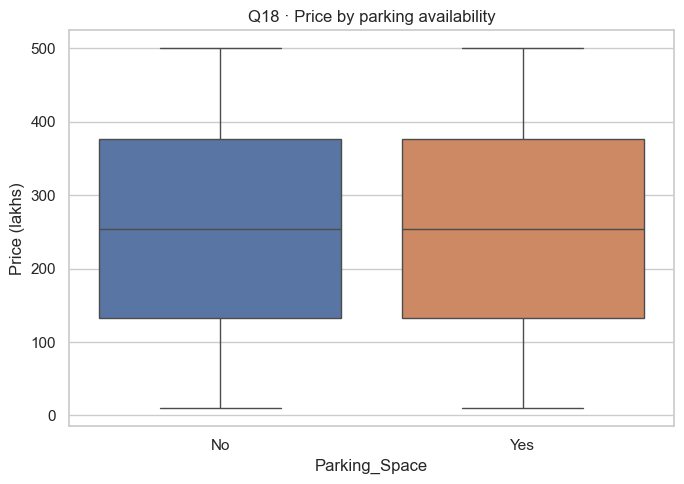

In [65]:
t18 = group_table(eda, "Parking_Space", "Price_in_Lakhs")
display(t18.round(2))
yes = eda.loc[eda["Parking_Space"] == "Yes", "Price_in_Lakhs"]; no = eda.loc[eda["Parking_Space"] == "No", "Price_in_Lakhs"]
diff = yes.mean() - no.mean()
se = np.sqrt(yes.var() / len(yes) + no.var() / len(no))
t_stat, p_val = stats.ttest_ind(yes, no, equal_var=False)
pooled_sd = np.sqrt((yes.var() + no.var()) / 2)
print(f"Mean price difference (Yes - No): {diff:.2f} lakhs, 95% CI [{diff - 1.96 * se:.2f}, {diff + 1.96 * se:.2f}]")
print(f"That is {diff / eda['Price_in_Lakhs'].mean() * 100:.2f}% of the overall mean price")
print(f"Welch t-test p-value: {p_val:.4f} | Cohen's d (effect size): {diff / pooled_sd:.4f}  (0.2 would be called 'small')")
print(f"Median difference (Yes - No): {yes.median() - no.median():.2f} lakhs")

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=eda, x="Parking_Space", y="Price_in_Lakhs", hue="Parking_Space", legend=False, order=["No", "Yes"], ax=ax)
ax.set_title("Q18 · Price by parking availability"); ax.set_ylabel("Price (lakhs)")
save_fig("q18_price_by_parking")

**Interpretation (based on the output above):** 
Properties with parking have a mean price of 254.75 lakhs against 254.43 without, a difference of **0.32 lakhs (0.12% of the mean)** with a 95% interval of −0.79 to +1.42, which includes zero. The Welch t-test gives p = 0.576 and the effect size (Cohen's d) is 0.0022, far below even a "small" 0.2. The medians differ by 0.99 lakhs (254.36 vs 253.37), which is also well within noise given the ±1 lakh uncertainty of a mean. **No detectable effect of parking on price.**

## Q19. How do amenities affect price per sq ft?
We test each of the 5 amenities separately (with vs without), then look at the *number* of amenities.  
Because we run 5 tests, we also show a **Bonferroni-adjusted p-value** (p × 5, capped at 1) — a safeguard, since some small p-values appear by luck when many tests are run.

,mean_with,mean_without,difference,ci_low,ci_high,diff_pct_of_overall_mean,p_value,p_bonferroni
amenity,,,,,,,,
Clubhouse,"13,069.6","13,041.2",28.4344,-76.0340,132.9029,0.2178,0.5937,1.0000
Garden,"13,064.6","13,048.7",15.8956,-88.7116,120.5027,0.1217,0.7658,1.0000
Gym,"13,097.5","12,999.5",98.0020,-6.4475,202.4516,0.7505,0.0659,0.3296
Playground,"13,048.9","13,072.4",-23.4866,-128.0760,81.1029,-0.1799,0.6598,1.0000
Pool,"13,072.7","13,036.6",36.0486,-68.4749,140.5721,0.2761,0.4991,1.0000


Price per sq ft by number of amenities:


,count,mean,median,std,ci95_half_width
Amenity_Count,,,,,
1,50106,"13,015.0","9,240.0","12,963.0",114.0000
2,49806,"13,059.0","9,242.0","13,095.0",115.0000
3,49862,"13,044.0","9,207.0","13,102.0",115.0000
4,50362,"13,071.0","9,250.0","13,112.0",115.0000
5,49864,"13,102.0","9,294.0","13,088.0",115.0000


Spearman rho (Amenity_Count vs price/sqft): 0.0025


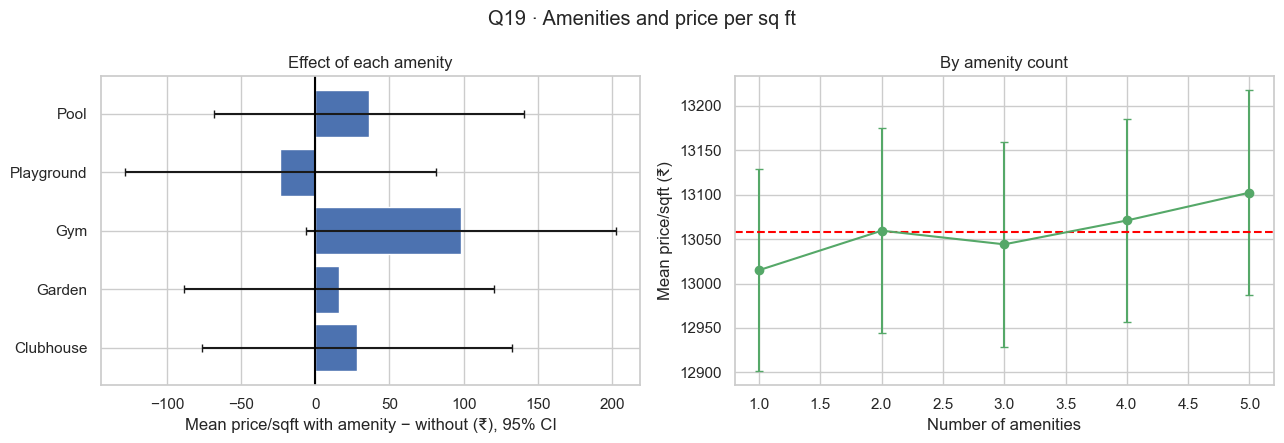

In [66]:
rows = []
for name in AMENITY_NAMES:
    has = eda.loc[eda[f"Has_{name}"] == 1, PPSF]; lacks = eda.loc[eda[f"Has_{name}"] == 0, PPSF]
    d = has.mean() - lacks.mean(); se = np.sqrt(has.var() / len(has) + lacks.var() / len(lacks))
    p = stats.ttest_ind(has, lacks, equal_var=False).pvalue
    rows.append({"amenity": name, "mean_with": has.mean(), "mean_without": lacks.mean(), "difference": d,
                 "ci_low": d - 1.96 * se, "ci_high": d + 1.96 * se, "diff_pct_of_overall_mean": 100 * d / eda[PPSF].mean(),
                 "p_value": p, "p_bonferroni": min(1.0, p * len(AMENITY_NAMES))})
t19 = pd.DataFrame(rows).set_index("amenity")
display(t19.round(4))

print("Price per sq ft by number of amenities:")
t19b = group_table(eda, "Amenity_Count", PPSF); display(t19b.round(0))
print("Spearman rho (Amenity_Count vs price/sqft):", round(stats.spearmanr(eda["Amenity_Count"], eda[PPSF])[0], 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(t19.index, t19["difference"], xerr=[t19["difference"] - t19["ci_low"], t19["ci_high"] - t19["difference"]], color="#4C72B0", capsize=3)
axes[0].axvline(0, color="black"); axes[0].set_xlabel("Mean price/sqft with amenity − without (₹), 95% CI"); axes[0].set_title("Effect of each amenity")
axes[1].errorbar(t19b.index, t19b["mean"], yerr=t19b["ci95_half_width"], marker="o", capsize=3, color="#55A868")
axes[1].axhline(eda[PPSF].mean(), color="red", linestyle="--"); axes[1].set_xlabel("Number of amenities"); axes[1].set_ylabel("Mean price/sqft (₹)")
axes[1].set_title("By amenity count")
fig.suptitle("Q19 · Amenities and price per sq ft")
save_fig("q19_amenities_vs_ppsf")

**Interpretation (based on the output above):** 
For each amenity, the difference in mean price per sq ft (with minus without) ranges from −₹23 to +₹98 (−0.18% to +0.75% of the overall mean), and **every 95% interval includes zero**. The smallest p-value is for the gym (0.066, or 0.330 after the Bonferroni adjustment), so none is significant. By amenity count, mean price per sq ft goes from ₹13,015 (1 amenity) to ₹13,102 (5 amenities); this ₹87 rise (0.67% of the overall mean) is smaller than the roughly ±₹115 interval of each group, and the rank correlation is 0.0025. **Amenities do not measurably affect price per sq ft here.**

## Q20. How does public transport accessibility relate to price per sq ft or investment potential?
The spec asks about "investment potential", but **no investment label exists** (Section 8). To give a *descriptive* answer without creating a target, we use a temporary, clearly-labelled **demo indicator**:

> `value_demo = 1` if a property's exact price per sq ft is **at or below the median of its own City × Property_Type group**.

This is **not** the future "Good Investment" label. It only says "cheaper per sq ft than similar properties". It is **not saved** in any dataset, and it does **not** use transport, so the comparison below is not circular. In Phase 3 any real label threshold must be computed from the **training set only**.

,count,mean,median,std,ci95_half_width
Low,83287,"13,086.0","9,265.0","13,081.0",89.0000
Medium,83008,"13,062.0","9,269.0","13,074.0",89.0000
High,83705,"13,027.0","9,205.0","13,060.0",88.0000


Kruskal-Wallis p-value: 0.6111 | Eta squared: 0.000003

Share of properties cheaper-than-peers (demo indicator), by transport level (%):
Public_Transport_Accessibility
Low      49.9000
Medium   49.8600
High     50.2800
Chi-square independence test: p = 0.1675


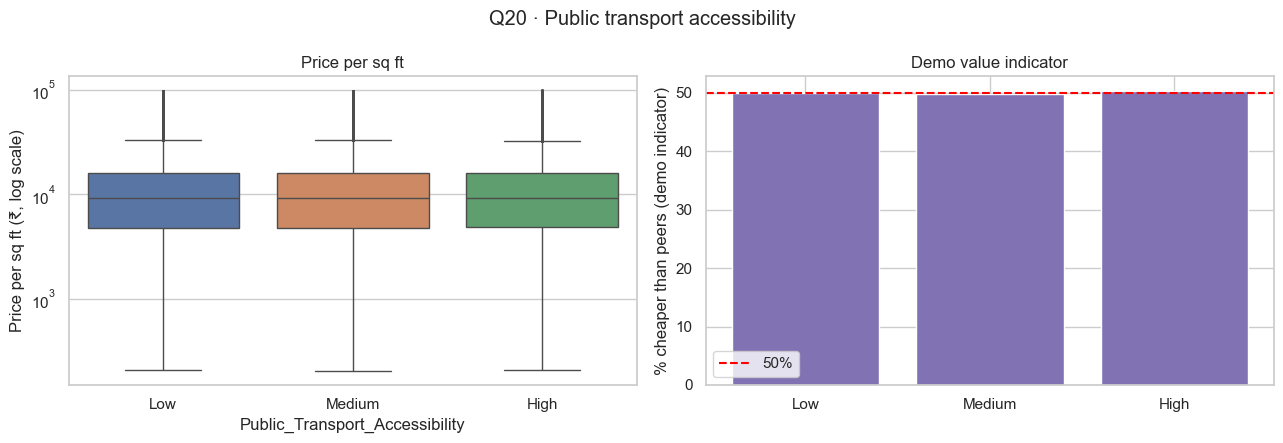

In [67]:
level_names = {0: "Low", 1: "Medium", 2: "High"}
t20 = group_table(eda, "Transport_Level", PPSF); t20.index = [level_names[i] for i in t20.index]
display(t20.round(0))
print("Kruskal-Wallis p-value:", f"{kruskal_p(eda, 'Transport_Level', PPSF):.4f}", "| Eta squared:", f"{eta_squared(eda, 'Transport_Level', PPSF):.6f}")

segment_median = eda.groupby(["City", "Property_Type"])["Price_per_SqFt_exact"].transform("median")
value_demo = (eda["Price_per_SqFt_exact"] <= segment_median).astype(int)       # temporary - NOT stored in any table
share = value_demo.groupby(eda["Public_Transport_Accessibility"]).mean().reindex(["Low", "Medium", "High"]) * 100
print("\nShare of properties cheaper-than-peers (demo indicator), by transport level (%):")
print(share.round(2).to_string())
chi2, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(eda["Public_Transport_Accessibility"], value_demo))
print(f"Chi-square independence test: p = {p_chi:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=eda, x="Public_Transport_Accessibility", y=PPSF, hue="Public_Transport_Accessibility", legend=False,
            order=["Low", "Medium", "High"], hue_order=["Low", "Medium", "High"], fliersize=1, ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_ylabel("Price per sq ft (₹, log scale)"); axes[0].set_title("Price per sq ft")
axes[1].bar(share.index, share.values, color="#8172B3"); axes[1].axhline(50, color="red", linestyle="--", label="50%")
axes[1].set_ylabel("% cheaper than peers (demo indicator)"); axes[1].set_title("Demo value indicator"); axes[1].legend()
fig.suptitle("Q20 · Public transport accessibility")
save_fig("q20_transport_accessibility")
del segment_median, value_demo

**Interpretation (based on the output above):** 
Mean price per sq ft is ₹13,086 (Low), ₹13,062 (Medium) and ₹13,027 (High) transport accessibility, with intervals of about ±₹89 (Kruskal-Wallis p = 0.611, η² = 0.000003): a slightly *decreasing* pattern, but far inside the noise. For the temporary "cheaper-than-peers" indicator, the shares are 49.90% (Low), 49.86% (Medium) and 50.28% (High), and the chi-square test gives p = 0.168. **Transport accessibility is unrelated to price per sq ft and to this indicator.** The indicator only measures "cheaper than similar properties"; it is not a measure of investment return.

---
## 8. Target feasibility analysis

The project needs two targets:

| Task | Target the spec asks for |
|---|---|
| Regression | `Future_Price_5Y` — the property price after 5 years |
| Classification | `Good_Investment` — yes / no |

This section checks **what the data can and cannot support**. We **do not create these columns**. Any numbers computed here are temporary illustrations and are **not saved** into any table.

### 8.1 Do the target columns exist in the CSV?

In [68]:
wanted_names = ["Future_Price_5Y", "Future_Price_SY", "Future_Price", "Good_Investment", "Investment_Label"]
print("Exact target column names present:", [c for c in wanted_names if c in df_raw.columns])

keywords = ["future", "invest", "target", "label", "growth", "return", "appreciat", "rent", "yield", "date", "sale", "listing", "month", "year"]
hits = [c for c in df_raw.columns if any(k in c.lower() for k in keywords)]
print("Columns whose name suggests a target, return, or date:", hits)

print("\nProperties per ID (every ID appears once -> one snapshot per property):", int(df_raw["ID"].value_counts().max()))
print("Year_Built is a construction year:", df_raw["Year_Built"].min(), "to", df_raw["Year_Built"].max(), "- not a sale/valuation date")
print("Columns that could give a price history (date, previous price, rent, appreciation):", "none")
check("No future-price column exists", not any(c in df_raw.columns for c in ["Future_Price_5Y", "Future_Price_SY", "Future_Price"]))
check("No good-investment label exists", "Good_Investment" not in df_raw.columns)

Exact target column names present: []
Columns whose name suggests a target, return, or date: ['Year_Built']

Properties per ID (every ID appears once -> one snapshot per property): 1
Year_Built is a construction year: 1990 to 2023 - not a sale/valuation date
Columns that could give a price history (date, previous price, rent, appreciation): none
PASS ✅ - No future-price column exists 
PASS ✅ - No good-investment label exists 


**Interpretation (based on the output above):** 
Neither target exists. No column called `Future_Price_5Y`, `Future_Price_SY` or `Good_Investment` is present, and the only column whose name hints at time is `Year_Built`, a **construction** year. Every ID appears exactly once, so there is one snapshot per property: no earlier or later price, no sale date, no rent, no appreciation. **A genuine five-year price (or an observed growth rate) cannot be taken or estimated from this file.**

### 8.2 Would a 5-year price depend on an *assumed* growth rate?
Without price history, the only way to get a "future price" is the formula **`Future = Current × (1 + r)^5`**, where `r` is a growth rate **we choose**. The table shows how strongly the answer depends on that choice (illustration only, not stored).

In [69]:
rows = []
for r in [0.00, 0.03, 0.05, 0.08, 0.10, 0.12]:
    mult = (1 + r) ** 5
    rows.append({"assumed_annual_growth": f"{r:.0%}", "5yr_multiplier": mult,
                 "median_current_price_lakhs": eda["Price_in_Lakhs"].median(),
                 "implied_median_future_price_lakhs": eda["Price_in_Lakhs"].median() * mult})
display(pd.DataFrame(rows).round(3))

demo_future = eda["Price_in_Lakhs"] * (1.08 ** 5)          # temporary, NOT stored
print("Spearman correlation between current price and this 'future price':", round(stats.spearmanr(eda["Price_in_Lakhs"], demo_future)[0], 6))
print("Ratio future/current is the same for every property:", np.allclose(demo_future / eda["Price_in_Lakhs"], 1.08 ** 5))
del demo_future

,assumed_annual_growth,5yr_multiplier,median_current_price_lakhs,implied_median_future_price_lakhs
0,0%,1.0000,253.8700,253.8700
1,3%,1.1590,253.8700,294.3050
2,5%,1.2760,253.8700,324.0100
3,8%,1.4690,253.8700,373.0180
4,10%,1.6110,253.8700,408.8600
5,12%,1.7620,253.8700,447.4060


Spearman correlation between current price and this 'future price': 1.0
Ratio future/current is the same for every property: True


**Interpretation (based on the output above):** 
Yes. The projected median price (from 253.87 lakhs today) ranges from 294.3 lakhs at 3% growth to 447.4 lakhs at 12% growth — the answer is decided by the rate we choose, not by the data. With a single rate, every property is multiplied by the same number (1.469 at 8%), so the "future price" has a rank correlation of exactly 1.0 with today's price. **A model that "predicts the future price" would really be predicting today's price times a constant**, and the projection is an *assumption*, not an observed outcome.

### 8.3 Would a "Good Investment" label have to be constructed?
Yes — there is no return, rent or appreciation column. The project PDF suggests three rules. We test how much they agree (illustration on the full data only; **any real threshold must later be computed from the training set only**, never from the test set).

Share labelled 'good' - Rule A (price <= median): 50.0 %
Share labelled 'good' - Rule B (price/sqft <= median): 50.0 %
Rules A and B give the same answer for 78.9 % of properties

Cross-tab of the two rules (rows = A, columns = B):


B: cheap per sqft,False,True
A: cheap price,,
False,98654,26345
True,26346,98655


,share_quality_only_%,share_value_AND_quality_%
quality_threshold,,
>= 1 of 5,96.6900,48.3500
>= 2 of 5,79.9300,39.9900
>= 3 of 5,47.5500,23.8200
>= 4 of 5,16.6500,8.3400
>= 5 of 5,2.5600,1.2700


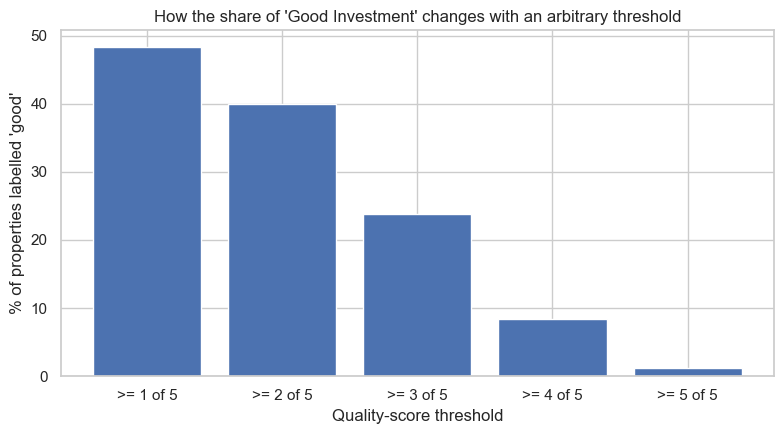

In [70]:
# Rule A: price at or below the overall median      Rule B: price per sq ft at or below the overall median
rule_a = eda["Price_in_Lakhs"] <= eda["Price_in_Lakhs"].median()
rule_b = eda["Price_per_SqFt_exact"] <= eda["Price_per_SqFt_exact"].median()
print("Share labelled 'good' - Rule A (price <= median):", round(rule_a.mean() * 100, 2), "%")
print("Share labelled 'good' - Rule B (price/sqft <= median):", round(rule_b.mean() * 100, 2), "%")
print("Rules A and B give the same answer for", round((rule_a == rule_b).mean() * 100, 1), "% of properties")
print("\nCross-tab of the two rules (rows = A, columns = B):")
display(pd.crosstab(rule_a.rename("A: cheap price"), rule_b.rename("B: cheap per sqft")))

# Rule C: multi-factor quality score (the five criteria suggested in the Phase 1 handoff)
quality = ((eda["BHK"] >= 3).astype(int) + (eda["Availability_Status"] == "Ready_to_Move").astype(int)
           + (eda["Parking_Space"] == "Yes").astype(int) + (eda["Security"] == "Yes").astype(int)
           + (eda["Public_Transport_Accessibility"] == "High").astype(int))
seg_median = eda.groupby(["City", "Property_Type"])["Price_per_SqFt_exact"].transform("median")
value_ok = eda["Price_per_SqFt_exact"] <= seg_median
rows = []
for k in range(1, 6):
    rows.append({"quality_threshold": f">= {k} of 5", "share_quality_only_%": (quality >= k).mean() * 100,
                 "share_value_AND_quality_%": (value_ok & (quality >= k)).mean() * 100})
tab = pd.DataFrame(rows).set_index("quality_threshold")
display(tab.round(2))

plt.figure(figsize=(8, 4.5))
plt.bar(tab.index, tab["share_value_AND_quality_%"], color="#4C72B0")
plt.ylabel("% of properties labelled 'good'"); plt.xlabel("Quality-score threshold")
plt.title("How the share of 'Good Investment' changes with an arbitrary threshold")
save_fig("08_label_prevalence_by_threshold")
del quality, seg_median, value_ok, rule_a, rule_b

**Interpretation (based on the output above):** 
- Rule A (price ≤ median) and Rule B (price per sq ft ≤ median) each call exactly half of the properties "good", but they **agree for only 78.9%** (52,691 properties get opposite labels). "Cheap" depends on how you measure it.
- For the multi-factor rule, the share of "good" properties swings from **48.35% (quality score ≥ 1) to 1.27% (score = 5)**, with 23.82% at ≥ 3. The threshold is a judgement call that changes class balance dramatically.
- All three rules are built from columns that could also be model inputs (price, size, BHK, parking, security, status, transport). A model given those columns would just rediscover our rule, so a high accuracy would prove only that the rule was recovered, **not that the model can identify good investments**.

### 8.4 Do the features carry information about price at all?
If the features cannot explain price, a model trained to predict price (or a future price built from it) cannot do much better than guessing the average — no matter how good the algorithm. We measure this **without training a model**:

- for each categorical column: **η²** (share of price variation explained) compared with the value expected **by pure chance** `(groups − 1) ÷ (rows − 1)`;
- for each numeric column: the Spearman rank correlation with price.

,groups,eta_squared,expected_by_chance,ratio_to_chance
column,,,,
Locality,500,0.002041,0.001996,1.0225
Amenities,325,0.001101,0.001296,0.8495
City,42,0.000190,0.000164,1.1599
State,20,0.000097,0.000076,1.2711
Property_Type,3,0.000022,0.000008,2.6972
Security,2,0.000015,0.000004,3.6260
Public_Transport_Accessibility,3,0.000009,0.000008,1.1742
Availability_Status,2,0.000008,0.000004,1.9703
Facing,4,0.000006,0.000012,0.5195


,spearman_with_price
Size_in_SqFt,-0.002500
Year_Built,0.002700
Age_of_Property,-0.002700
Floor_No,-0.001700
Total_Floors,0.001300
Nearby_Schools,0.000100
Nearby_Hospitals,-0.002800
Amenity_Count,0.001000
Infra_Score,-0.001600


Largest |Spearman| with price: 0.0028 | largest eta squared: 0.002041


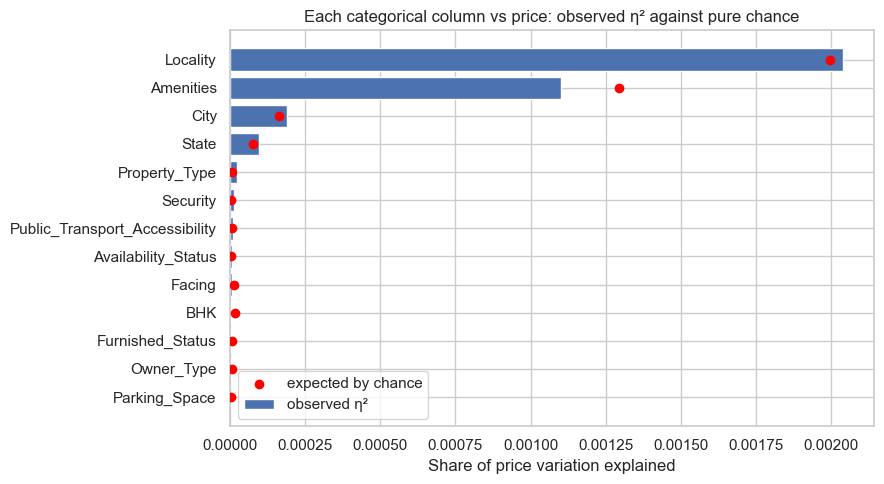

In [71]:
cat_for_price = ["State", "City", "Locality", "Property_Type", "Furnished_Status", "Public_Transport_Accessibility",
                 "Parking_Space", "Security", "Amenities", "Facing", "Owner_Type", "Availability_Status", "BHK"]
rows = []
for col in cat_for_price:
    n_groups = eda[col].nunique()
    rows.append({"column": col, "groups": n_groups, "eta_squared": eta_squared(eda, col, "Price_in_Lakhs"),
                 "expected_by_chance": (n_groups - 1) / (len(eda) - 1)})
eta_table = pd.DataFrame(rows).set_index("column")
eta_table["ratio_to_chance"] = eta_table["eta_squared"] / eta_table["expected_by_chance"]
display(eta_table.sort_values("eta_squared", ascending=False).round(6))

num_for_price = ["Size_in_SqFt", "Year_Built", "Age_of_Property", "Floor_No", "Total_Floors", "Nearby_Schools",
                 "Nearby_Hospitals", "Amenity_Count", "Infra_Score"]
sp_price = pd.Series({c: stats.spearmanr(eda[c], eda["Price_in_Lakhs"])[0] for c in num_for_price}, name="spearman_with_price")
display(sp_price.round(4).to_frame())
print("Largest |Spearman| with price:", round(sp_price.abs().max(), 4), "| largest eta squared:", round(eta_table["eta_squared"].max(), 6))

fig, ax = plt.subplots(figsize=(9, 5))
plot_df = eta_table.sort_values("eta_squared")
ax.barh(plot_df.index, plot_df["eta_squared"], label="observed η²", color="#4C72B0")
ax.scatter(plot_df["expected_by_chance"], plot_df.index, color="red", zorder=3, label="expected by chance")
ax.set_xlabel("Share of price variation explained"); ax.set_title("Each categorical column vs price: observed η² against pure chance"); ax.legend()
save_fig("08_eta_squared_vs_chance")

**Interpretation (based on the output above):** 
- The share of price variation explained by any single categorical column is tiny: the largest is `Locality` at 0.002041, against 0.001996 expected by pure chance (ratio 1.02); `City` is 0.000190 against 0.000164, `State` 0.000097 against 0.000076, and `Amenities` is even *below* chance. All remaining columns have η² ≤ 0.000022 (under 0.003% of the variation). A few small-group columns show a ratio above 1 (Security 3.6, Property_Type 2.7), but their absolute values are negligible and ratios are unstable when the chance level itself is almost zero.
- For numeric columns the largest absolute rank correlation with price is **0.0028**.
- **Implication:** none of the available features visibly explains price. A model asked to predict price, or a future price built from it, is therefore expected to do little better than guessing the average. This is a strong *hint* and **not proof** (a model could in principle exploit combinations of features that single-column checks miss), so Phase 3 must test it against a "predict the average" baseline before drawing conclusions.

### 8.5 What each target can — and cannot — legitimately claim

| Item | Honest statement |
|---|---|
| **Future price (regression)** | A projection of *today's price under a growth rate we assumed*. It is **not** an observed future outcome. Any model of it is really a model of today's price. |
| **Model score on that target** | Shows how well the model recovers *our formula and price signal*, **not** how well it forecasts the market. If `Price_in_Lakhs` is an input, a near-perfect score is **leakage**, not skill. |
| **Good Investment (classification)** | "Meets a rule we wrote". It does **not** say the property will appreciate or earn a return. |
| **Model score on that label** | If the label is built from columns that are also model inputs, the model simply re-learns the rule and "high accuracy" proves nothing. |

**Test-set rule for Phase 3:** split first; compute medians, thresholds and any encodings **only on the training rows**; apply them unchanged to the test rows.

### 8.6 Unresolved decisions (not decided in this notebook)
1. **Growth rate** for the regression target (Phase 1 recommended a fixed 8% as a *labelled assumption*).
2. **Investment-label rule and thresholds** (Phase 1 recommended value-vs-segment-median plus a quality score ≥ 3 of 5; the thresholds are judgement calls, and Section 8.3 shows how sensitive the label share is to them).
3. Whether `Price_in_Lakhs` may be a **regression input**.
4. Treatment of **`Floor_No` / `Total_Floors`** (flag and exclude is recommended).
5. Whether **`Locality`** is used in models.
6. The **weighting of `Infra_Score`**.
7. How to **word the project's claims**, given Section 8.4.

## 9. Final findings

### 9.1 Reconciliation with the Phase 1 handoff
Before summarising, we recompute the key Phase 1 numbers from the data and compare them. Any **FLAG** means Phase 1 and this notebook disagree and the methodology should be revisited before Phase 3.

In [72]:
exact = df_raw["Price_in_Lakhs"] / df_raw["Size_in_SqFt"]
reported = df_raw["Price_per_SqFt"]
q1_, q3_ = reported.quantile([0.25, 0.75]); stored_outliers = int((reported > q3_ + 1.5 * (q3_ - q1_)).sum())

check("Shape is 250,000 x 23", df_raw.shape == (250000, 23), str(df_raw.shape))
check("Missing cells = 0", int(df_raw.isna().sum().sum()) == 0)
check("Duplicate rows = 0", int(df_raw.duplicated().sum()) == 0)
check("Floor_No > Total_Floors = 116,304 rows (Phase 1)", int((df_raw["Floor_No"] > df_raw["Total_Floors"]).sum()) == 116304,
      f"found {int((df_raw['Floor_No'] > df_raw['Total_Floors']).sum()):,}")
check("Under_Construction = 125,035 rows (Phase 1)", int((df_raw["Availability_Status"] == "Under_Construction").sum()) == 125035)
check("Stored Price_per_SqFt = 0 in 2,534 rows (Phase 1)", int((reported == 0).sum()) == 2534, f"found {int((reported == 0).sum()):,}")
check("Stored price/sqft IQR outliers = 20,020 (Phase 1)", stored_outliers == 20020, f"found {stored_outliers:,}")
check("Age_of_Property = 2025 - Year_Built (Phase 1)", bool(((2025 - df_raw["Year_Built"]) == df_raw["Age_of_Property"]).all()))
check("Median price 253.87 lakhs (Phase 1)", abs(df_raw["Price_in_Lakhs"].median() - 253.87) < 0.01, f"found {df_raw['Price_in_Lakhs'].median():.2f}")
check("City median prices span 247.97-259.52 (Phase 1)",
      abs(df_raw.groupby("City")["Price_in_Lakhs"].median().min() - 247.97) < 0.01 and abs(df_raw.groupby("City")["Price_in_Lakhs"].median().max() - 259.52) < 0.01)
cities_per_loc = df_raw.groupby("Locality")["City"].nunique()
check("All 500 localities occur in all 42 cities (Phase 1 statement)", int(cities_per_loc.min()) == 42,
      f"{int((cities_per_loc == 42).sum())} of 500 do; {', '.join(cities_per_loc[cities_per_loc < 42].index)} appears in only {int(cities_per_loc.min())} cities")
check("Every locality occurs in at least 41 of 42 cities (Phase 1 conclusion 'labels are not geographic' still holds)", int(cities_per_loc.min()) >= 41)

checks_df = pd.DataFrame(CHECKS)
print()
print("Checks so far:", len(checks_df), "| PASS:", int((checks_df.status == "PASS").sum()), "| FLAG:", int((checks_df.status == "FLAG").sum()))

PASS ✅ - Shape is 250,000 x 23 | (250000, 23)
PASS ✅ - Missing cells = 0 
PASS ✅ - Duplicate rows = 0 
PASS ✅ - Floor_No > Total_Floors = 116,304 rows (Phase 1) | found 116,304
PASS ✅ - Under_Construction = 125,035 rows (Phase 1) 
PASS ✅ - Stored Price_per_SqFt = 0 in 2,534 rows (Phase 1) | found 2,534
PASS ✅ - Stored price/sqft IQR outliers = 20,020 (Phase 1) | found 20,020
PASS ✅ - Age_of_Property = 2025 - Year_Built (Phase 1) 
PASS ✅ - Median price 253.87 lakhs (Phase 1) | found 253.87
PASS ✅ - City median prices span 247.97-259.52 (Phase 1) 
FLAG ⚠️ - All 500 localities occur in all 42 cities (Phase 1 statement) | 499 of 500 do; Locality_117 appears in only 41 cities
PASS ✅ - Every locality occurs in at least 41 of 42 cities (Phase 1 conclusion 'labels are not geographic' still holds) 

Checks so far: 22 | PASS: 21 | FLAG: 1


**Interpretation (based on the output above):** 
All recomputed Phase 1 numbers match (shape, missing, duplicates, 116,304 impossible floors, 125,035 under-construction rows, 2,534 zero price-per-sqft rows, 20,020 stored-price-per-sqft outliers, the 2025 age rule, the median price and the city median range), with **one exception, flagged above**: Phase 1 said all 500 localities occur in all 42 cities, but the exact figure is 499 of 500 (`Locality_117` occurs in 41). The conclusion drawn from it does not change, so **no methodology change is needed**.

Three scope notes (not contradictions in the data):
1. Phase 1's outlier count (20,020) refers to the *stored* price per sq ft; the exact ratio gives 19,723 (7.89%). Phase 1 already planned to use the exact ratio.
2. The Phase 1 handoff described "Phase 2" as both notebooks plus model training. You have defined this phase as notebook 01 only, so **model training moves to Phase 3**.
3. The Phase 1 handoff said not to write a model-ready CSV before the train/test split. The CSVs saved here contain **no targets and no fitted statistics**, so they do not create leakage; the split and target construction still belong to Phase 3.

### 9.2 Major findings (supported by the output above)

**Dataset and data quality**
- 250,000 rows × 23 columns, **0 missing values, 0 duplicate rows, 0 duplicate IDs**; text categories are clean.
- **Floor_No > Total_Floors in 116,304 rows (46.52%)**: consistent with two unrelated random numbers, not repairable.
- **All 125,035 `Under_Construction` rows have past build years** (1990–2023).
- Stored `Price_per_SqFt` is rounded (100 distinct values; 2,534 zeros, 1.01%); the exact ratio fixes this.
- Price per sq ft has 19,723 high-side IQR outliers (7.89%) that come from small sizes; price and size have none.
- `Age_of_Property` = 2025 − `Year_Built` in every row (fully redundant).
- 500 locality labels repeat across the 42 cities (499 of 500 in all 42); they carry no geographic meaning.
- Size is unrelated to BHK (10,080 rows have under 200 sq ft per BHK).

**What the 20 EDA questions showed**
- Price (10–500 lakhs) and size (500–5,000 sq ft) are **evenly spread**, not skewed like real markets (Q1, Q2).
- **No feature shows a meaningful relationship with price or price per sq ft**: property type, size, state, city, furnishing, facing, parking, amenities, schools, hospitals and transport all differ by at most about 3% of the overall mean, with overlapping confidence intervals (Q3–Q4, Q6–Q7, Q12–Q15, Q18–Q20).
- The only strong correlations are between columns linked by definition (Q11).
- The "top 5 most expensive localities" is random noise (Q10); owner type and availability status are split in nearly equal shares (Q16, Q17).

**Target feasibility (Section 8)**
- No future-price column, no investment label, no dates: both targets would have to be constructed from assumptions.
- A projected price equals today's price times a constant; a "good investment" label depends on arbitrary thresholds (its share ranges from 48% to 1%).
- No available feature visibly explains price (largest η² ≈ chance level; largest |Spearman| 0.0028).

**Useful features**
`Price_per_SqFt_exact`, five amenity flags, `Amenity_Count`, `Transport_Level`, `Infra_Score` (descriptive), plus the flags documenting data-quality problems.

**Limitations**
- The data behaves like **randomly generated data** (independent, evenly spread columns, contradictory floors and statuses). We cannot prove its origin, but results should not be presented as real-market insight.
- Any model score on the constructed targets reflects the construction rule, not real investment performance.

### 9.3 Recommendations for Phase 3

1. **Decide the open items first** (Section 8.6): growth rate, label rule and thresholds, whether price may be a regression input, floor-column treatment, locality use, `Infra_Score` weighting, and how to word the project claims.
2. **Split before anything is fitted.** Create the train/test split first, then compute medians, thresholds and any encodings from the **training rows only** and apply them unchanged to the test rows.
3. **Start from `engineered_features.csv`** and the `feature_dictionary.csv` decisions. Keep price-derived columns out of model inputs, and keep the location summaries as separate tables.
4. **Always include baselines** ("predict the average" and "predict the majority class") and report every model against them, since Section 8.4 suggests little signal.
5. **Run an honest primary experiment and a clearly labelled "rule-recovery" experiment** for classification, so a high score caused by rebuilding the label rule is never presented as skill.
6. **Be transparent in the report**: state that targets are constructed, the growth rate is an assumption, and the dataset behaves like synthetic data.
7. **Print and record library versions** (Section 2) and freeze them when saving model pipelines.
8. For the Streamlit phase later, consider showing a growth-rate **scenario table** (no ML needed) and displaying the investment rule that was applied.

### 9.4 What we learned — summary

The dataset is **structurally clean but statistically empty**. It has no missing values or duplicates and its definitions mostly hold (age and price per sq ft follow their formulas, apart from rounding), yet it contains contradictory records (impossible floor numbers, under-construction buildings from the 1990s) and columns that behave as if they were generated independently of one another. We answered all 20 EDA questions with real outputs: almost every comparison showed differences of only a few percent, well inside the confidence intervals, and the strongest correlations came from definitions, not behaviour. Neither a five-year price nor an investment label exists, so both targets must be built from assumptions, and any resulting model score would show how well a rule or an assumed growth rate is recovered — not how well real investment outcomes are predicted. The next phase can proceed, but only with the target definitions confirmed, a leak-free split, baseline comparisons, and honest wording of what the models can claim.

## 10. Export outputs

We save these files in the `outputs/` folder (in Colab: the *Files* panel on the left, under `/content/outputs`):

| File | What it is |
|---|---|
| `cleaned_housing_data.csv` | `df_clean`: the 23 original columns **unchanged** plus 3 added columns. 250,000 rows. |
| `engineered_features.csv` | `df_feat`: the cleaned data plus the derived features. **No target columns.** |
| `feature_dictionary.csv` | Keep / exclude decision and reason for every column |
| `data_quality_report.csv` | The Section 4 issue log |
| `cleaning_log.csv` | Every Section 5 step |
| `state_summary.csv`, `city_summary.csv`, `locality_summary.csv` | Location price summaries (kept separate on purpose) |
| `notebook_checks.csv` | All PASS/FLAG checks |
| `figures/` and `eda_figures.zip` | Every chart as a PNG |
| `phase2_outputs.zip` | Everything above in one download (saved next to the `outputs/` folder) |

In [73]:
df_clean.to_csv(os.path.join(OUTPUT_DIR, "cleaned_housing_data.csv"), index=False)
df_feat.to_csv(os.path.join(OUTPUT_DIR, "engineered_features.csv"), index=False)
feature_dictionary.to_csv(os.path.join(OUTPUT_DIR, "feature_dictionary.csv"), index=False)
quality_report.to_csv(os.path.join(OUTPUT_DIR, "data_quality_report.csv"), index=False)
cleaning_log_df.to_csv(os.path.join(OUTPUT_DIR, "cleaning_log.csv"), index=False)
state_summary.to_csv(os.path.join(OUTPUT_DIR, "state_summary.csv"))
city_summary.to_csv(os.path.join(OUTPUT_DIR, "city_summary.csv"))
locality_summary.to_csv(os.path.join(OUTPUT_DIR, "locality_summary.csv"))
pd.DataFrame(CHECKS).to_csv(os.path.join(OUTPUT_DIR, "notebook_checks.csv"), index=False)
print("CSV files written.")

CSV files written.


In [74]:
def zip_folder(zip_name, folder, pattern=None):
    with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
        for root, _, files_ in os.walk(folder):
            for f in files_:
                if pattern is None or pattern(f):
                    full = os.path.join(root, f)
                    z.write(full, os.path.relpath(full, start=os.path.dirname(folder) or "."))

zip_folder(os.path.join(OUTPUT_DIR, "eda_figures.zip"), FIG_DIR)
zip_folder("phase2_outputs.zip", OUTPUT_DIR, pattern=lambda f: f != "eda_figures.zip")
print("Figures saved:", len([f for f in os.listdir(FIG_DIR) if f.endswith(".png")]))

Figures saved: 24


### 10.1 Verify the saved files
We list every file with its size and re-read the two big CSVs to confirm that what was saved is what we expect.

In [75]:
listing = []
for root, _, files_ in os.walk(OUTPUT_DIR):
    for f in sorted(files_):
        full = os.path.join(root, f)
        if "figures" in root and f.endswith(".png"):
            continue
        listing.append({"file": os.path.relpath(full), "size_MB": round(os.path.getsize(full) / 1024**2, 3)})
listing.append({"file": "phase2_outputs.zip", "size_MB": round(os.path.getsize("phase2_outputs.zip") / 1024**2, 3)})
display(pd.DataFrame(listing))

back_clean = pd.read_csv(os.path.join(OUTPUT_DIR, "cleaned_housing_data.csv"))
back_feat = pd.read_csv(os.path.join(OUTPUT_DIR, "engineered_features.csv"))
check("Saved cleaned file has 250,000 rows and 26 columns", back_clean.shape == (250000, 26), str(back_clean.shape))
check("Saved features file has the same 250,000 rows", len(back_feat) == 250000, str(back_feat.shape))
check("No target columns were written", not any(c in back_feat.columns for c in ["Good_Investment", "Future_Price_5Y", "Future_Price"]))
same_numbers = np.allclose(back_clean[numeric_cols].to_numpy(dtype=float), df_raw[numeric_cols].to_numpy(dtype=float))
same_text = back_clean[categorical_cols].astype(str).equals(df_raw[categorical_cols].astype(str))
check("Saved original columns equal the raw data after a save-and-reload", same_numbers and same_text)
del back_clean, back_feat
pd.DataFrame(CHECKS).to_csv(os.path.join(OUTPUT_DIR, "notebook_checks.csv"), index=False)
final = pd.DataFrame(CHECKS)
print("\nFINAL CHECK SUMMARY -> PASS:", int((final.status == "PASS").sum()), "| FLAG:", int((final.status == "FLAG").sum()))
display(final[final.status == "FLAG"] if (final.status == "FLAG").any() else pd.DataFrame({"result": ["No FLAGs - every check passed"]}))

,file,size_MB
0,outputs\city_summary.csv,0.003000
1,outputs\cleaned_housing_data.csv,46.9330
2,outputs\cleaning_log.csv,0.001000
3,outputs\data_quality_report.csv,0.001000
4,outputs\eda_figures.zip,1.4520
5,outputs\engineered_features.csv,57.2270
6,outputs\feature_dictionary.csv,0.002000
7,outputs\locality_summary.csv,0.0410
8,outputs\notebook_checks.csv,0.001000
9,outputs\state_summary.csv,0.002000


PASS ✅ - Saved cleaned file has 250,000 rows and 26 columns | (250000, 26)
PASS ✅ - Saved features file has the same 250,000 rows | (250000, 36)
PASS ✅ - No target columns were written 
PASS ✅ - Saved original columns equal the raw data after a save-and-reload 

FINAL CHECK SUMMARY -> PASS: 25 | FLAG: 1


,check,status,detail
20,All 500 localities occur in all 42 cities (Phase 1 statement),FLAG,499 of 500 do; Locality_117 appears in only 41 cities


### 10.2 Download the files
Run the cell below to download one ZIP with everything. In Colab your browser will ask permission to download. If the pop-up is blocked, open the **Files** panel (folder icon on the left), open the `/content` folder, right-click `phase2_outputs.zip` and choose **Download**. Individual files are inside `/content/outputs`.

In [76]:
if IN_COLAB:
    from google.colab import files
    files.download("phase2_outputs.zip")
else:
    print("Not running in Colab. The files are in the 'outputs' folder and in phase2_outputs.zip next to this notebook.")

Not running in Colab. The files are in the 'outputs' folder and in phase2_outputs.zip next to this notebook.


---
**End of notebook.** Next: Phase 3 (target definition on the training set only, preprocessing pipelines, model training with MLflow) once the unresolved decisions in Section 8.6 are confirmed.